# SmartServe Food Intelligence

## 06 — Model Deployment and Forecasting

### Objective

This notebook prepares the selected machine learning model for practical
demand forecasting across restaurant locations.

The workflow covers:

- Loading the saved Gradient Boosting model
- Preparing new prediction data
- Generating demand forecasts
- Evaluating forecast outputs
- Converting predictions into inventory recommendations
- Supporting restaurant preparation planning
- Exporting forecasting results

The trained model is not modified in this notebook.

In [1]:
# 1. Environment Setup and Model Loading

import sys
from pathlib import Path

import pandas as pd
import numpy as np

# Project directory
PROJECT_ROOT = Path.cwd().parent

# Add project directory to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Import reusable deployment functions
from src.model_deployment import (
    load_trained_model,
    get_model_information
)

# Define model path
MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "gradient_boosting_model.pkl"
)

# Load trained model
deployment_model = load_trained_model(MODEL_PATH)

# Retrieve model information
model_information = get_model_information(
    deployment_model
)

print("SMARTSERVE MODEL DEPLOYMENT")
print("=" * 55)

print("Project directory:", PROJECT_ROOT)
print("Model path:", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())

for key, value in model_information.items():
    print(f"{key}: {value}")

print("\nMODEL LOADING COMPLETED")

2026-11-17 18:03:30,068 | INFO | src.model_deployment | Model file validation completed: d:\Data Analysis Projects\SmartServe-Food-Intelligence\models\gradient_boosting_model.pkl
2026-11-17 18:03:30,075 | INFO | src.model_deployment | Loading trained model: d:\Data Analysis Projects\SmartServe-Food-Intelligence\models\gradient_boosting_model.pkl
2026-11-17 18:03:39,070 | INFO | src.model_deployment | Successfully loaded model: GradientBoostingRegressor
2026-11-17 18:03:39,072 | INFO | src.model_deployment | Retrieved model information: GradientBoostingRegressor


SMARTSERVE MODEL DEPLOYMENT
Project directory: d:\Data Analysis Projects\SmartServe-Food-Intelligence
Model path: d:\Data Analysis Projects\SmartServe-Food-Intelligence\models\gradient_boosting_model.pkl
Model exists: True
model_name: GradientBoostingRegressor
model_module: sklearn.ensemble._gb
prediction_supported: True

MODEL LOADING COMPLETED


In [2]:
# 2. Model Feature Inspection
# Identify the features required by the trained model.

model_features = deployment_model.feature_names_in_

feature_count = len(model_features)

feature_information = pd.DataFrame({
    "Feature_Name": model_features
})

print("MODEL FEATURE INSPECTION")
print("=" * 55)

print("Model:", type(deployment_model).__name__)
print("Total required features:", feature_count)

print("\nFIRST 15 MODEL FEATURES")

display(feature_information.head(15))

print("\nMODEL FEATURE INSPECTION COMPLETED")

MODEL FEATURE INSPECTION
Model: GradientBoostingRegressor
Total required features: 110

FIRST 15 MODEL FEATURES


,Feature_Name
0,calendar_year
1,calendar_quarter
2,calendar_month
3,calendar_week
4,calendar_day
5,calendar_day_of_week
6,calendar_is_weekend
7,calendar_is_holiday
8,store_seating_capacity
9,store_average_daily_customers



MODEL FEATURE INSPECTION COMPLETED


In [3]:
# 3. Load Processed Training Features
# Load the training feature dataset used during model development.

TRAIN_FEATURES_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "model"
    / "X_train.csv"
)

training_features = pd.read_csv(
    TRAIN_FEATURES_PATH
)

print("TRAINING FEATURE DATA")
print("=" * 55)

print("Dataset shape:", training_features.shape)
print("Total columns:", len(training_features.columns))
print("Total records:", len(training_features))

print("\nFIRST 10 RECORDS")

display(training_features.head(10))

print("\nTRAINING FEATURE DATA LOADED SUCCESSFULLY")

TRAINING FEATURE DATA
Dataset shape: (7200, 110)
Total columns: 110
Total records: 7200

FIRST 10 RECORDS


,calendar_year,calendar_quarter,calendar_month,calendar_week,calendar_day,calendar_day_of_week,calendar_is_weekend,calendar_is_holiday,store_seating_capacity,store_average_daily_customers,...,product_subcategory_Shake,product_subcategory_Sides,product_subcategory_Smoothie,product_size_Regular,product_size_Slice,product_size_Small,weather_weather_condition_Cloudy,weather_weather_condition_Partly Cloudy,weather_weather_condition_Rainy,weather_weather_condition_Sunny
0,2025,1,1,1,1,3,0,1,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2025,1,1,1,2,4,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,2025,1,1,1,3,5,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,2025,1,1,1,4,6,1,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2025,1,1,1,5,7,1,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
5,2025,1,1,2,6,1,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
6,2025,1,1,2,7,2,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
7,2025,1,1,2,8,3,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
8,2025,1,1,2,9,4,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
9,2025,1,1,2,10,5,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0



TRAINING FEATURE DATA LOADED SUCCESSFULLY


In [4]:
# 4. Inspect All Model Features
# Group model features by their naming prefixes.

feature_groups = {
    "Calendar": [
        col for col in model_features
        if col.startswith("calendar_")
    ],
    "Store": [
        col for col in model_features
        if col.startswith("store_")
    ],
    "Product": [
        col for col in model_features
        if col.startswith("product_")
    ],
    "Weather": [
        col for col in model_features
        if col.startswith("weather_")
    ],
    "Historical Demand": [
        col for col in model_features
        if col.startswith("sales_")
    ]
}

print("MODEL FEATURE GROUPS")
print("=" * 55)

for group_name, columns in feature_groups.items():
    print(f"\n{group_name}: {len(columns)} features")

    for column in columns:
        print("  -", column)

print("\nFEATURE GROUP INSPECTION COMPLETED")

MODEL FEATURE GROUPS

Calendar: 23 features
  - calendar_year
  - calendar_quarter
  - calendar_month
  - calendar_week
  - calendar_day
  - calendar_day_of_week
  - calendar_is_weekend
  - calendar_is_holiday
  - calendar_month_name_February
  - calendar_month_name_January
  - calendar_month_name_March
  - calendar_day_name_Friday
  - calendar_day_name_Monday
  - calendar_day_name_Saturday
  - calendar_day_name_Sunday
  - calendar_day_name_Thursday
  - calendar_day_name_Tuesday
  - calendar_day_name_Wednesday
  - calendar_holiday_name_International Mother Language Day
  - calendar_holiday_name_New Year's Day
  - calendar_holiday_name_No Holiday
  - calendar_season_Spring
  - calendar_season_Winter

Store: 26 features
  - store_seating_capacity
  - store_average_daily_customers
  - store_operating_days
  - store_store_name_SmartServe Chattogram 2
  - store_store_name_SmartServe Dhaka 1
  - store_store_name_SmartServe Khulna 5
  - store_store_name_SmartServe Rajshahi 4
  - store_store_n

In [5]:
# 5. Inspect Historical Demand Features
# Identify all lag, rolling, and missing-value features.

historical_features = feature_groups["Historical Demand"]

historical_feature_report = pd.DataFrame({
    "Feature_Name": historical_features
})

print("HISTORICAL DEMAND FEATURES")
print("=" * 55)

print("Total historical demand features:", len(historical_features))

display(historical_feature_report)

print("\nHISTORICAL DEMAND FEATURE INSPECTION COMPLETED")

HISTORICAL DEMAND FEATURES
Total historical demand features: 14


,Feature_Name
0,sales_lag_1
1,sales_lag_7
2,sales_lag_14
3,sales_lag_28
4,sales_rolling_mean_7
5,sales_rolling_mean_14
6,sales_rolling_mean_28
7,sales_lag_1_missing
8,sales_lag_7_missing
9,sales_lag_14_missing



HISTORICAL DEMAND FEATURE INSPECTION COMPLETED


In [6]:
# 6. Inspect Available Forecasting Data Sources
# Identify processed datasets available for forecasting.

PROCESSED_DATA_PATH = PROJECT_ROOT / "data" / "processed"

print("AVAILABLE PROCESSED DATASETS")
print("=" * 55)

for file_path in sorted(PROCESSED_DATA_PATH.rglob("*")):

    if file_path.is_file():

        relative_path = file_path.relative_to(PROJECT_ROOT)

        print(relative_path)

print("\nPROCESSED DATA SOURCE INSPECTION COMPLETED")

AVAILABLE PROCESSED DATASETS
data\processed\data_quality_report.csv
data\processed\model\X_test.csv
data\processed\model\X_train.csv
data\processed\model\y_test.csv
data\processed\model\y_train.csv

PROCESSED DATA SOURCE INSPECTION COMPLETED


In [7]:
# 7. Locate Historical Sales Data
# Identify the original sales dataset for forecasting.

DATA_PATH = PROJECT_ROOT / "data"

print("DATA DIRECTORY STRUCTURE")
print("=" * 55)

for folder_name in ["raw", "interim", "processed"]:

    folder_path = DATA_PATH / folder_name

    print(f"\n{folder_name.upper()}")

    if folder_path.exists():

        for file_path in sorted(folder_path.rglob("*")):

            if file_path.is_file():
                print("  ", file_path.relative_to(PROJECT_ROOT))

    else:
        print("  Directory does not exist")

print("\nDATA SOURCE LOCATION INSPECTION COMPLETED")

DATA DIRECTORY STRUCTURE

RAW
   data\raw\dim_customer.csv
   data\raw\dim_date.csv
   data\raw\dim_holiday.csv
   data\raw\dim_product.csv
   data\raw\dim_promotion.csv
   data\raw\dim_store.csv
   data\raw\dim_weather.csv
   data\raw\fact_inventory.csv
   data\raw\fact_preparation.csv
   data\raw\fact_sales.csv
   data\raw\fact_waste.csv

INTERIM
  Directory does not exist

PROCESSED
   data\processed\data_quality_report.csv
   data\processed\model\X_test.csv
   data\processed\model\X_train.csv
   data\processed\model\y_test.csv
   data\processed\model\y_train.csv

DATA SOURCE LOCATION INSPECTION COMPLETED


In [8]:
# 8. Inspect Historical Sales Data
# Examine the original sales dataset before forecasting preparation.

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"

sales_data = pd.read_csv(
    RAW_DATA_PATH / "fact_sales.csv"
)

print("HISTORICAL SALES DATA")
print("=" * 55)

print("Dataset shape:", sales_data.shape)
print("Total records:", len(sales_data))

print("\nCOLUMN NAMES")
print(sales_data.columns.tolist())

print("\nDATA TYPES")
display(sales_data.dtypes.to_frame("Data_Type"))

print("\nFIRST 10 RECORDS")
display(sales_data.head(10))

print("\nHISTORICAL SALES DATA INSPECTION COMPLETED")

HISTORICAL SALES DATA
Dataset shape: (122318, 15)
Total records: 122318

COLUMN NAMES
['sales_id', 'order_id', 'date_id', 'store_id', 'customer_id', 'product_id', 'promotion_id', 'quantity', 'unit_price', 'discount_amount', 'gross_sales', 'net_sales', 'cost_amount', 'profit_amount', 'payment_method']

DATA TYPES


,Data_Type
sales_id,str
order_id,str
date_id,int64
store_id,str
customer_id,str
product_id,str
promotion_id,str
quantity,int64
unit_price,float64
discount_amount,float64



FIRST 10 RECORDS


,sales_id,order_id,date_id,store_id,customer_id,product_id,promotion_id,quantity,unit_price,discount_amount,gross_sales,net_sales,cost_amount,profit_amount,payment_method
0,SAL00000001,ORD00000001,20250101,ST001,CUS00522,PRD001,PROMO007,3,120.0,36.0,360.0,324.0,135.0,189.0,Cash
1,SAL00000002,ORD00000002,20250101,ST001,CUS00094,PRD001,PROMO007,2,120.0,24.0,240.0,216.0,90.0,126.0,Cash
2,SAL00000003,ORD00000003,20250101,ST001,CUS00613,PRD001,PROMO007,1,120.0,12.0,120.0,108.0,45.0,63.0,Mobile Banking
3,SAL00000004,ORD00000004,20250101,ST001,CUS00556,PRD001,PROMO007,1,120.0,12.0,120.0,108.0,45.0,63.0,Mobile Banking
4,SAL00000005,ORD00000005,20250101,ST001,CUS00026,PRD001,PROMO007,4,120.0,48.0,480.0,432.0,180.0,252.0,Cash
5,SAL00000006,ORD00000006,20250101,ST001,CUS00518,PRD001,PROMO007,1,120.0,12.0,120.0,108.0,45.0,63.0,Cash
6,SAL00000007,ORD00000007,20250101,ST001,CUS00286,PRD001,PROMO007,2,120.0,24.0,240.0,216.0,90.0,126.0,Cash
7,SAL00000008,ORD00000008,20250101,ST001,CUS00291,PRD001,PROMO007,1,120.0,12.0,120.0,108.0,45.0,63.0,Mobile Banking
8,SAL00000009,ORD00000009,20250101,ST001,CUS00022,PRD001,PROMO007,2,120.0,24.0,240.0,216.0,90.0,126.0,Mobile Banking
9,SAL00000010,ORD00000010,20250101,ST001,CUS00750,PRD001,PROMO007,4,120.0,48.0,480.0,432.0,180.0,252.0,Cash



HISTORICAL SALES DATA INSPECTION COMPLETED


In [10]:
# RESTORE NOTEBOOK ENVIRONMENT
# Reload the original datasets and project paths.

import sys
from pathlib import Path

import pandas as pd
import numpy as np
import importlib

# Locate the project root
current_path = Path.cwd()

PROJECT_ROOT = next(
    (
        path for path in [current_path, *current_path.parents]
        if (path / "data" / "raw" / "fact_sales.csv").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the SmartServe project directory."
    )

# Define data directory
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"

# Add project root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Reload forecasting module
import src.forecasting
importlib.reload(src.forecasting)

# Load original datasets
sales_data = pd.read_csv(
    RAW_DATA_PATH / "fact_sales.csv"
)

date_data = pd.read_csv(
    RAW_DATA_PATH / "dim_date.csv"
)

print("NOTEBOOK ENVIRONMENT RESTORED")
print("=" * 55)

print("Project root:", PROJECT_ROOT)
print("Sales data shape:", sales_data.shape)
print("Date data shape:", date_data.shape)

print("\nENVIRONMENT RESTORATION COMPLETED")

NOTEBOOK ENVIRONMENT RESTORED
Project root: d:\Data Analysis Projects\SmartServe-Food-Intelligence
Sales data shape: (122318, 15)
Date data shape: (90, 14)

ENVIRONMENT RESTORATION COMPLETED


In [11]:
# 9. Inspect Sales Date and Store-Product Coverage
# Verify the historical period and demand-series coverage.

sales_date_summary = sales_data.merge(
    date_data[["date_id", "full_date"]],
    on="date_id",
    how="left"
)

sales_date_summary["full_date"] = pd.to_datetime(
    sales_date_summary["full_date"]
)

print("HISTORICAL SALES COVERAGE")
print("=" * 55)

print(
    "First sales date:",
    sales_date_summary["full_date"].min()
)

print(
    "Last sales date:",
    sales_date_summary["full_date"].max()
)

print(
    "Unique sales dates:",
    sales_date_summary["date_id"].nunique()
)

print(
    "Unique stores:",
    sales_data["store_id"].nunique()
)

print(
    "Unique products:",
    sales_data["product_id"].nunique()
)

print(
    "Unique store-product combinations:",
    sales_data[["store_id", "product_id"]]
    .drop_duplicates()
    .shape[0]
)

print(
    "Unmatched date records:",
    sales_date_summary["full_date"].isna().sum()
)

print("\nHISTORICAL SALES COVERAGE INSPECTION COMPLETED")

HISTORICAL SALES COVERAGE
First sales date: 2025-01-01 00:00:00
Last sales date: 2025-03-31 00:00:00
Unique sales dates: 90
Unique stores: 5
Unique products: 20
Unique store-product combinations: 100
Unmatched date records: 0

HISTORICAL SALES COVERAGE INSPECTION COMPLETED


In [12]:
# 10. Aggregate Daily Product Demand
# Use the reusable forecasting module to aggregate sales.

from src.forecasting import aggregate_daily_demand

daily_demand = aggregate_daily_demand(
    sales_data=sales_data,
    date_data=date_data
)

print("DAILY DEMAND AGGREGATION")
print("=" * 55)

print("Dataset shape:", daily_demand.shape)
print("Daily demand records:", len(daily_demand))
print("Unique stores:", daily_demand["store_id"].nunique())
print("Unique products:", daily_demand["product_id"].nunique())

print(
    "Store-product combinations:",
    daily_demand[["store_id", "product_id"]]
    .drop_duplicates()
    .shape[0]
)

print("\nFIRST 10 RECORDS")

display(daily_demand.head(10))

print("\nDAILY DEMAND AGGREGATION COMPLETED")

2026-11-17 18:05:07,900 | INFO | src.forecasting | Starting daily demand aggregation


2026-11-17 18:05:08,076 | INFO | src.forecasting | Daily demand aggregation completed: 9000 records


DAILY DEMAND AGGREGATION
Dataset shape: (9000, 5)
Daily demand records: 9000
Unique stores: 5
Unique products: 20
Store-product combinations: 100

FIRST 10 RECORDS


,date_id,store_id,product_id,sales_qty,full_date
0,20250101,ST001,PRD001,48,2025-01-01
1,20250102,ST001,PRD001,45,2025-01-02
2,20250103,ST001,PRD001,77,2025-01-03
3,20250104,ST001,PRD001,92,2025-01-04
4,20250105,ST001,PRD001,75,2025-01-05
5,20250106,ST001,PRD001,77,2025-01-06
6,20250107,ST001,PRD001,37,2025-01-07
7,20250108,ST001,PRD001,60,2025-01-08
8,20250109,ST001,PRD001,88,2025-01-09
9,20250110,ST001,PRD001,59,2025-01-10



DAILY DEMAND AGGREGATION COMPLETED


In [13]:
# 11. Generate Historical Demand Features
# Generate lag, rolling mean, and missing-value features.

import importlib
import src.forecasting

importlib.reload(src.forecasting)

from src.forecasting import create_historical_demand_features

demand_features = create_historical_demand_features(
    daily_demand
)

historical_feature_columns = [
    column for column in demand_features.columns
    if column.startswith("sales_lag_")
    or column.startswith("sales_rolling_mean_")
]

print("HISTORICAL DEMAND FEATURE GENERATION")
print("=" * 55)

print("Dataset shape:", demand_features.shape)

print(
    "Historical demand features:",
    len(historical_feature_columns)
)

print("\nHISTORICAL FEATURE COLUMNS")

for column in historical_feature_columns:
    print("-", column)

print("\nMISSING VALUE SUMMARY")

display(
    demand_features[
        historical_feature_columns
    ].isna().sum().to_frame("Missing_Count")
)

print("\nFIRST 10 FEATURED RECORDS")

display(demand_features.head(10))

print("\nHISTORICAL DEMAND FEATURE GENERATION COMPLETED")

2026-11-17 18:05:11,422 | INFO | src.forecasting | Creating historical demand features
2026-11-17 18:05:12,625 | INFO | src.forecasting | Historical demand feature generation completed


HISTORICAL DEMAND FEATURE GENERATION
Dataset shape: (9000, 19)
Historical demand features: 14

HISTORICAL FEATURE COLUMNS
- sales_lag_1
- sales_lag_1_missing
- sales_lag_7
- sales_lag_7_missing
- sales_lag_14
- sales_lag_14_missing
- sales_lag_28
- sales_lag_28_missing
- sales_rolling_mean_7
- sales_rolling_mean_7_missing
- sales_rolling_mean_14
- sales_rolling_mean_14_missing
- sales_rolling_mean_28
- sales_rolling_mean_28_missing

MISSING VALUE SUMMARY


,Missing_Count
sales_lag_1,100
sales_lag_1_missing,0
sales_lag_7,700
sales_lag_7_missing,0
sales_lag_14,1400
sales_lag_14_missing,0
sales_lag_28,2800
sales_lag_28_missing,0
sales_rolling_mean_7,700
sales_rolling_mean_7_missing,0



FIRST 10 FEATURED RECORDS


,date_id,store_id,product_id,sales_qty,full_date,sales_lag_1,sales_lag_1_missing,sales_lag_7,sales_lag_7_missing,sales_lag_14,sales_lag_14_missing,sales_lag_28,sales_lag_28_missing,sales_rolling_mean_7,sales_rolling_mean_7_missing,sales_rolling_mean_14,sales_rolling_mean_14_missing,sales_rolling_mean_28,sales_rolling_mean_28_missing
0,20250101,ST001,PRD001,48,2025-01-01,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1
1,20250102,ST001,PRD001,45,2025-01-02,48.0,0,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1
2,20250103,ST001,PRD001,77,2025-01-03,45.0,0,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1
3,20250104,ST001,PRD001,92,2025-01-04,77.0,0,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1
4,20250105,ST001,PRD001,75,2025-01-05,92.0,0,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1
5,20250106,ST001,PRD001,77,2025-01-06,75.0,0,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1
6,20250107,ST001,PRD001,37,2025-01-07,77.0,0,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1,NaN,1
7,20250108,ST001,PRD001,60,2025-01-08,37.0,0,48.0,0,NaN,1,NaN,1,64.428571,0,NaN,1,NaN,1
8,20250109,ST001,PRD001,88,2025-01-09,60.0,0,45.0,0,NaN,1,NaN,1,66.142857,0,NaN,1,NaN,1
9,20250110,ST001,PRD001,59,2025-01-10,88.0,0,77.0,0,NaN,1,NaN,1,72.285714,0,NaN,1,NaN,1



HISTORICAL DEMAND FEATURE GENERATION COMPLETED


In [14]:
# 12. Load Supporting Dimension Data
# Load the dimension tables required for forecasting features.

# Load store information
store_data = pd.read_csv(
    RAW_DATA_PATH / "dim_store.csv"
)

# Load product information
product_data = pd.read_csv(
    RAW_DATA_PATH / "dim_product.csv"
)

# Load weather information
weather_data = pd.read_csv(
    RAW_DATA_PATH / "dim_weather.csv"
)

print("SUPPORTING DIMENSION DATA")
print("=" * 55)

print("\nSTORE DATA")
print("Shape:", store_data.shape)
print("Columns:", store_data.columns.tolist())

print("\nPRODUCT DATA")
print("Shape:", product_data.shape)
print("Columns:", product_data.columns.tolist())

print("\nWEATHER DATA")
print("Shape:", weather_data.shape)
print("Columns:", weather_data.columns.tolist())

print("\nSUPPORTING DIMENSION DATA LOADING COMPLETED")

SUPPORTING DIMENSION DATA

STORE DATA
Shape: (5, 9)
Columns: ['store_id', 'store_name', 'city', 'area', 'store_type', 'opening_date', 'seating_capacity', 'average_daily_customers', 'manager_region']

PRODUCT DATA
Shape: (20, 10)
Columns: ['product_id', 'product_name', 'category', 'subcategory', 'size', 'unit_cost', 'selling_price', 'shelf_life_hours', 'preparation_time', 'active_flag']

WEATHER DATA
Shape: (450, 7)
Columns: ['weather_id', 'date_id', 'store_id', 'temperature', 'rainfall', 'humidity', 'weather_condition']

SUPPORTING DIMENSION DATA LOADING COMPLETED


In [15]:
# 13. Validate Supporting Dimension Data
# Check missing values, duplicate records, and key uniqueness.

dimension_datasets = {
    "Store": (store_data, "store_id"),
    "Product": (product_data, "product_id"),
    "Weather": (weather_data, "weather_id")
}

print("SUPPORTING DIMENSION DATA VALIDATION")
print("=" * 65)

for dataset_name, (dataset, primary_key) in dimension_datasets.items():

    print(f"\n{dataset_name.upper()} DATA")
    print("-" * 55)

    print("Total records:", len(dataset))
    print("Missing values:", dataset.isna().sum().sum())
    print("Duplicate rows:", dataset.duplicated().sum())

    print(
        "Duplicate primary keys:",
        dataset[primary_key].duplicated().sum()
    )

    print(
        "Unique primary keys:",
        dataset[primary_key].nunique()
    )

    print(
        "Primary key missing values:",
        dataset[primary_key].isna().sum()
    )

print("\nSUPPORTING DIMENSION DATA VALIDATION COMPLETED")

SUPPORTING DIMENSION DATA VALIDATION

STORE DATA
-------------------------------------------------------
Total records: 5
Missing values: 0
Duplicate rows: 0
Duplicate primary keys: 0
Unique primary keys: 5
Primary key missing values: 0

PRODUCT DATA
-------------------------------------------------------
Total records: 20
Missing values: 0
Duplicate rows: 0
Duplicate primary keys: 0
Unique primary keys: 20
Primary key missing values: 0

WEATHER DATA
-------------------------------------------------------
Total records: 450
Missing values: 0
Duplicate rows: 0
Duplicate primary keys: 0
Unique primary keys: 450
Primary key missing values: 0

SUPPORTING DIMENSION DATA VALIDATION COMPLETED


In [16]:
# 14. Merge Supporting Dimension Data
# Enrich historical demand features with store, product, and weather information.

# Merge store attributes
forecasting_data = demand_features.merge(
    store_data,
    on="store_id",
    how="left",
    validate="many_to_one"
)

# Merge product attributes
forecasting_data = forecasting_data.merge(
    product_data,
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Merge weather attributes
forecasting_data = forecasting_data.merge(
    weather_data,
    on=["date_id", "store_id"],
    how="left",
    validate="many_to_one"
)

print("SUPPORTING DIMENSION DATA MERGING")
print("=" * 55)

print("Original demand feature shape:", demand_features.shape)
print("Merged forecasting data shape:", forecasting_data.shape)

print("\nMISSING VALUES AFTER MERGING")
display(
    forecasting_data.isna().sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nFIRST 5 RECORDS")
display(forecasting_data.head())

print("\nSUPPORTING DIMENSION DATA MERGING COMPLETED")

SUPPORTING DIMENSION DATA MERGING
Original demand feature shape: (9000, 19)
Merged forecasting data shape: (9000, 41)

MISSING VALUES AFTER MERGING


,Missing_Count
sales_lag_1,100
sales_lag_7,700
sales_lag_14,1400
sales_lag_28,2800
sales_rolling_mean_7,700
sales_rolling_mean_14,1400
sales_rolling_mean_28,2800



FIRST 5 RECORDS


,date_id,store_id,product_id,sales_qty,full_date,sales_lag_1,sales_lag_1_missing,sales_lag_7,sales_lag_7_missing,sales_lag_14,...,unit_cost,selling_price,shelf_life_hours,preparation_time,active_flag,weather_id,temperature,rainfall,humidity,weather_condition
0,20250101,ST001,PRD001,48,2025-01-01,NaN,1,NaN,1,NaN,...,45,120,4,3,True,WTH20250101ST001,23.0,0.0,48,Sunny
1,20250102,ST001,PRD001,45,2025-01-02,48.0,0,NaN,1,NaN,...,45,120,4,3,True,WTH20250102ST001,23.9,3.4,74,Cloudy
2,20250103,ST001,PRD001,77,2025-01-03,45.0,0,NaN,1,NaN,...,45,120,4,3,True,WTH20250103ST001,22.6,5.8,77,Cloudy
3,20250104,ST001,PRD001,92,2025-01-04,77.0,0,NaN,1,NaN,...,45,120,4,3,True,WTH20250104ST001,25.4,3.0,74,Cloudy
4,20250105,ST001,PRD001,75,2025-01-05,92.0,0,NaN,1,NaN,...,45,120,4,3,True,WTH20250105ST001,23.0,2.1,76,Partly Cloudy



SUPPORTING DIMENSION DATA MERGING COMPLETED


In [17]:
# 15. Validate Merged Forecasting Data
# Verify row counts, key coverage, and dimension matching.

print("MERGED FORECASTING DATA VALIDATION")
print("=" * 60)

# 1. Record count validation
print("\nRECORD COUNT VALIDATION")

print("Original demand records:", len(demand_features))
print("Merged forecasting records:", len(forecasting_data))

print(
    "Record count preserved:",
    len(demand_features) == len(forecasting_data)
)

# 2. Store and product coverage
print("\nDIMENSION COVERAGE")

print(
    "Unique stores:",
    forecasting_data["store_id"].nunique()
)

print(
    "Unique products:",
    forecasting_data["product_id"].nunique()
)

print(
    "Store-product combinations:",
    forecasting_data[["store_id", "product_id"]]
    .drop_duplicates()
    .shape[0]
)

# 3. Dimension matching validation
print("\nDIMENSION MATCHING")

print(
    "Missing store names:",
    forecasting_data["store_name"].isna().sum()
)

print(
    "Missing product names:",
    forecasting_data["product_name"].isna().sum()
)

print(
    "Missing weather IDs:",
    forecasting_data["weather_id"].isna().sum()
)

# 4. Duplicate record validation
print("\nDUPLICATE VALIDATION")

print(
    "Duplicate date-store-product records:",
    forecasting_data.duplicated(
        subset=["date_id", "store_id", "product_id"]
    ).sum()
)

print("\nMERGED FORECASTING DATA VALIDATION COMPLETED")

MERGED FORECASTING DATA VALIDATION

RECORD COUNT VALIDATION
Original demand records: 9000
Merged forecasting records: 9000
Record count preserved: True

DIMENSION COVERAGE
Unique stores: 5
Unique products: 20
Store-product combinations: 100

DIMENSION MATCHING
Missing store names: 0
Missing product names: 0
Missing weather IDs: 0

DUPLICATE VALIDATION
Duplicate date-store-product records: 0

MERGED FORECASTING DATA VALIDATION COMPLETED


In [18]:
# 16. Generate Calendar Features
# Merge calendar attributes into the forecasting dataset.

# Select calendar columns
calendar_columns = [
    "date_id",
    "year",
    "quarter",
    "month",
    "week",
    "day",
    "day_of_week",
    "is_weekend",
    "is_holiday",
    "season"
]

calendar_features = date_data[calendar_columns].copy()

# Rename columns to match the model training feature structure
calendar_features = calendar_features.rename(
    columns={
        column: f"calendar_{column}"
        for column in calendar_columns
        if column != "date_id"
    }
)

# Merge calendar features
forecasting_data = forecasting_data.merge(
    calendar_features,
    on="date_id",
    how="left",
    validate="many_to_one"
)

print("CALENDAR FEATURE GENERATION")
print("=" * 55)

print("Calendar features added:", len(calendar_columns) - 1)
print("Forecasting dataset shape:", forecasting_data.shape)

print("\nCALENDAR FEATURE COLUMNS")
for column in calendar_features.columns:
    if column != "date_id":
        print("-", column)

print("\nMissing calendar values:")
display(
    forecasting_data[
        [column for column in calendar_features.columns if column != "date_id"]
    ].isna().sum().to_frame("Missing_Count")
)

print("\nCALENDAR FEATURE GENERATION COMPLETED")

CALENDAR FEATURE GENERATION
Calendar features added: 9
Forecasting dataset shape: (9000, 50)

CALENDAR FEATURE COLUMNS
- calendar_year
- calendar_quarter
- calendar_month
- calendar_week
- calendar_day
- calendar_day_of_week
- calendar_is_weekend
- calendar_is_holiday
- calendar_season

Missing calendar values:


,Missing_Count
calendar_year,0
calendar_quarter,0
calendar_month,0
calendar_week,0
calendar_day,0
calendar_day_of_week,0
calendar_is_weekend,0
calendar_is_holiday,0
calendar_season,0



CALENDAR FEATURE GENERATION COMPLETED


In [19]:
# 17. Inspect Forecasting Feature Coverage
# Compare the available forecasting columns with the trained model requirements.

required_model_features = list(
    deployment_model.feature_names_in_
)

available_columns = set(forecasting_data.columns)

available_model_features = [
    column for column in required_model_features
    if column in available_columns
]

missing_model_features = [
    column for column in required_model_features
    if column not in available_columns
]

print("FORECASTING FEATURE COVERAGE")
print("=" * 60)

print("Required model features:", len(required_model_features))
print("Currently available features:", len(available_model_features))
print("Features still missing:", len(missing_model_features))

print("\nAVAILABLE MODEL FEATURES")
for column in available_model_features:
    print("-", column)

print("\nMISSING MODEL FEATURES")
for column in missing_model_features:
    print("-", column)

print("\nFORECASTING FEATURE COVERAGE INSPECTION COMPLETED")

FORECASTING FEATURE COVERAGE
Required model features: 110
Currently available features: 22
Features still missing: 88

AVAILABLE MODEL FEATURES
- calendar_year
- calendar_quarter
- calendar_month
- calendar_week
- calendar_day
- calendar_day_of_week
- calendar_is_weekend
- calendar_is_holiday
- sales_lag_1
- sales_lag_7
- sales_lag_14
- sales_lag_28
- sales_rolling_mean_7
- sales_rolling_mean_14
- sales_rolling_mean_28
- sales_lag_1_missing
- sales_lag_7_missing
- sales_lag_14_missing
- sales_lag_28_missing
- sales_rolling_mean_7_missing
- sales_rolling_mean_14_missing
- sales_rolling_mean_28_missing

MISSING MODEL FEATURES
- store_seating_capacity
- store_average_daily_customers
- product_unit_cost
- product_selling_price
- product_shelf_life_hours
- product_preparation_time
- product_active_flag
- weather_temperature
- weather_rainfall
- weather_humidity
- store_operating_days
- calendar_month_name_February
- calendar_month_name_January
- calendar_month_name_March
- calendar_day_name

In [20]:
# 18. Categorize Missing Model Features
# Group missing model features by their original feature prefixes.

missing_feature_groups = {
    "Calendar": [],
    "Store": [],
    "Product": [],
    "Weather": [],
    "Other": []
}

for column in missing_model_features:

    if column.startswith("calendar_"):
        missing_feature_groups["Calendar"].append(column)

    elif column.startswith("store_"):
        missing_feature_groups["Store"].append(column)

    elif column.startswith("product_"):
        missing_feature_groups["Product"].append(column)

    elif column.startswith("weather_"):
        missing_feature_groups["Weather"].append(column)

    else:
        missing_feature_groups["Other"].append(column)


print("MISSING MODEL FEATURE CATEGORIES")
print("=" * 60)

for group_name, columns in missing_feature_groups.items():

    print(f"\n{group_name.upper()} FEATURES")
    print("-" * 50)
    print("Count:", len(columns))

    for column in columns:
        print("-", column)

print("\nMISSING FEATURE CATEGORY INSPECTION COMPLETED")

MISSING MODEL FEATURE CATEGORIES

CALENDAR FEATURES
--------------------------------------------------
Count: 15
- calendar_month_name_February
- calendar_month_name_January
- calendar_month_name_March
- calendar_day_name_Friday
- calendar_day_name_Monday
- calendar_day_name_Saturday
- calendar_day_name_Sunday
- calendar_day_name_Thursday
- calendar_day_name_Tuesday
- calendar_day_name_Wednesday
- calendar_holiday_name_International Mother Language Day
- calendar_holiday_name_New Year's Day
- calendar_holiday_name_No Holiday
- calendar_season_Spring
- calendar_season_Winter

STORE FEATURES
--------------------------------------------------
Count: 26
- store_seating_capacity
- store_average_daily_customers
- store_operating_days
- store_store_name_SmartServe Chattogram 2
- store_store_name_SmartServe Dhaka 1
- store_store_name_SmartServe Khulna 5
- store_store_name_SmartServe Rajshahi 4
- store_store_name_SmartServe Sylhet 3
- store_city_Chattogram
- store_city_Dhaka
- store_city_Khulna

In [21]:
# 19. Display Complete Missing Feature Groups
# Print every missing model feature for implementation planning.

for group_name, columns in missing_feature_groups.items():

    print(f"\n{group_name.upper()} FEATURES")
    print("=" * 65)
    print("Total:", len(columns))

    for index, column in enumerate(columns, start=1):
        print(f"{index:02d}. {column}")

print("\nTOTAL MISSING FEATURES:", len(missing_model_features))


CALENDAR FEATURES
Total: 15
01. calendar_month_name_February
02. calendar_month_name_January
03. calendar_month_name_March
04. calendar_day_name_Friday
05. calendar_day_name_Monday
06. calendar_day_name_Saturday
07. calendar_day_name_Sunday
08. calendar_day_name_Thursday
09. calendar_day_name_Tuesday
10. calendar_day_name_Wednesday
11. calendar_holiday_name_International Mother Language Day
12. calendar_holiday_name_New Year's Day
13. calendar_holiday_name_No Holiday
14. calendar_season_Spring
15. calendar_season_Winter

STORE FEATURES
Total: 26
01. store_seating_capacity
02. store_average_daily_customers
03. store_operating_days
04. store_store_name_SmartServe Chattogram 2
05. store_store_name_SmartServe Dhaka 1
06. store_store_name_SmartServe Khulna 5
07. store_store_name_SmartServe Rajshahi 4
08. store_store_name_SmartServe Sylhet 3
09. store_city_Chattogram
10. store_city_Dhaka
11. store_city_Khulna
12. store_city_Rajshahi
13. store_city_Sylhet
14. store_area_Business District
15.

In [22]:
# 19. Display Missing Store Features

print("MISSING STORE FEATURES")
print("=" * 60)

for index, column in enumerate(
    missing_feature_groups["Store"],
    start=1
):
    print(f"{index:02d}. {column}")

print("\nTotal:", len(missing_feature_groups["Store"]))

MISSING STORE FEATURES
01. store_seating_capacity
02. store_average_daily_customers
03. store_operating_days
04. store_store_name_SmartServe Chattogram 2
05. store_store_name_SmartServe Dhaka 1
06. store_store_name_SmartServe Khulna 5
07. store_store_name_SmartServe Rajshahi 4
08. store_store_name_SmartServe Sylhet 3
09. store_city_Chattogram
10. store_city_Dhaka
11. store_city_Khulna
12. store_city_Rajshahi
13. store_city_Sylhet
14. store_area_Business District
15. store_area_Downtown
16. store_area_Residential Area
17. store_area_Shopping Mall
18. store_area_University Area
19. store_store_type_Express
20. store_store_type_Flagship
21. store_store_type_Standard
22. store_manager_region_Central
23. store_manager_region_East
24. store_manager_region_North
25. store_manager_region_South
26. store_manager_region_West

Total: 26


In [23]:
# 20. Display Missing Product Features

print("MISSING PRODUCT FEATURES")
print("=" * 60)

for index, column in enumerate(
    missing_feature_groups["Product"],
    start=1
):
    print(f"{index:02d}. {column}")

print("\nTotal:", len(missing_feature_groups["Product"]))

MISSING PRODUCT FEATURES
01. product_unit_cost
02. product_selling_price
03. product_shelf_life_hours
04. product_preparation_time
05. product_active_flag
06. product_product_name_Americano
07. product_product_name_Beef Burger
08. product_product_name_Blueberry Muffin
09. product_product_name_Cappuccino
10. product_product_name_Cheesecake
11. product_product_name_Chicken Burger
12. product_product_name_Chicken Sandwich
13. product_product_name_Chocolate Cake
14. product_product_name_Chocolate Cookie
15. product_product_name_Chocolate Shake
16. product_product_name_Croissant
17. product_product_name_Espresso
18. product_product_name_French Fries
19. product_product_name_Iced Coffee
20. product_product_name_Iced Latte
21. product_product_name_Latte
22. product_product_name_Lemonade
23. product_product_name_Mango Smoothie
24. product_product_name_Mocha
25. product_product_name_Veggie Sandwich
26. product_category_Beverage
27. product_category_Dessert
28. product_category_Food
29. product_

In [24]:
# 21. Display Remaining Product Features

product_missing_features = missing_feature_groups["Product"]

print("PRODUCT FEATURES — COMPLETE LIST")
print("=" * 65)

for index, column in enumerate(
    product_missing_features[20:],
    start=21
):
    print(f"{index:02d}. {column}")

print("\nTotal product features:", len(product_missing_features))

PRODUCT FEATURES — COMPLETE LIST
21. product_product_name_Latte
22. product_product_name_Lemonade
23. product_product_name_Mango Smoothie
24. product_product_name_Mocha
25. product_product_name_Veggie Sandwich
26. product_category_Beverage
27. product_category_Dessert
28. product_category_Food
29. product_subcategory_Bakery
30. product_subcategory_Burger
31. product_subcategory_Cake
32. product_subcategory_Coffee
33. product_subcategory_Cold Drinks
34. product_subcategory_Sandwich
35. product_subcategory_Shake
36. product_subcategory_Sides
37. product_subcategory_Smoothie
38. product_size_Regular
39. product_size_Slice
40. product_size_Small

Total product features: 40


In [25]:
# 22. Display Missing Weather Features

print("MISSING WEATHER FEATURES")
print("=" * 60)

for index, column in enumerate(
    missing_feature_groups["Weather"],
    start=1
):
    print(f"{index:02d}. {column}")

print("\nTotal:", len(missing_feature_groups["Weather"]))

MISSING WEATHER FEATURES
01. weather_temperature
02. weather_rainfall
03. weather_humidity
04. weather_weather_condition_Cloudy
05. weather_weather_condition_Partly Cloudy
06. weather_weather_condition_Rainy
07. weather_weather_condition_Sunny

Total: 7


In [26]:
# 23. Identify Training Data Variable

print("CURRENT TRAINING DATA VARIABLES")
print("=" * 55)

for variable_name in ["X_train", "X_train_data", "train_data"]:
    if variable_name in globals():
        variable = globals()[variable_name]
        print(
            f"{variable_name}:",
            type(variable).__name__,
            getattr(variable, "shape", "No shape")
        )
    else:
        print(f"{variable_name}: Not defined")

CURRENT TRAINING DATA VARIABLES
X_train: Not defined
X_train_data: Not defined
train_data: Not defined


In [27]:
# 23. Load Training Feature Data
# Reload the original training features for comparison.

X_train_data = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "model" / "X_train.csv"
)

print("TRAINING FEATURE DATA LOADED")
print("=" * 55)

print("Dataset shape:", X_train_data.shape)
print("Total training records:", len(X_train_data))
print("Total training features:", len(X_train_data.columns))

print("\nFIRST 5 RECORDS")
display(X_train_data.head())

print("\nTRAINING FEATURE DATA LOADING COMPLETED")

TRAINING FEATURE DATA LOADED
Dataset shape: (7200, 110)
Total training records: 7200
Total training features: 110

FIRST 5 RECORDS


,calendar_year,calendar_quarter,calendar_month,calendar_week,calendar_day,calendar_day_of_week,calendar_is_weekend,calendar_is_holiday,store_seating_capacity,store_average_daily_customers,...,product_subcategory_Shake,product_subcategory_Sides,product_subcategory_Smoothie,product_size_Regular,product_size_Slice,product_size_Small,weather_weather_condition_Cloudy,weather_weather_condition_Partly Cloudy,weather_weather_condition_Rainy,weather_weather_condition_Sunny
0,2025,1,1,1,1,3,0,1,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2025,1,1,1,2,4,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,2025,1,1,1,3,5,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
3,2025,1,1,1,4,6,1,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,2025,1,1,1,5,7,1,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0



TRAINING FEATURE DATA LOADING COMPLETED


In [28]:
# 24. Inspect Training Feature Data Types
# Examine the original training feature data types.

print("TRAINING FEATURE DATA TYPE INSPECTION")
print("=" * 60)

print("Training dataset shape:", X_train_data.shape)

print("\nFEATURE DATA TYPES")

display(
    X_train_data.dtypes
    .value_counts()
    .to_frame("Feature_Count")
)

print("\nNUMERICAL FEATURE SUMMARY")

display(
    X_train_data.describe().T
)

print("\nTRAINING FEATURE DATA TYPE INSPECTION COMPLETED")

TRAINING FEATURE DATA TYPE INSPECTION
Training dataset shape: (7200, 110)

FEATURE DATA TYPES


,Feature_Count
float64,86
int64,24



NUMERICAL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
calendar_year,7200.0,2025.000000,0.000000,2025.0,2025.00,2025.0,2025.00,2025.0
calendar_quarter,7200.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
calendar_month,7200.0,1.750000,0.740734,1.0,1.00,2.0,2.00,3.0
calendar_week,7200.0,5.930556,2.992450,1.0,3.00,6.0,8.25,11.0
calendar_day,7200.0,13.791667,8.542870,1.0,6.75,12.5,21.00,31.0
...,...,...,...,...,...,...,...,...
product_size_Small,7200.0,0.050000,0.217960,0.0,0.00,0.0,0.00,1.0
weather_weather_condition_Cloudy,7200.0,0.200000,0.400028,0.0,0.00,0.0,0.00,1.0
weather_weather_condition_Partly Cloudy,7200.0,0.261111,0.439271,0.0,0.00,0.0,1.00,1.0
weather_weather_condition_Rainy,7200.0,0.083333,0.276405,0.0,0.00,0.0,0.00,1.0



TRAINING FEATURE DATA TYPE INSPECTION COMPLETED


In [29]:
# 25. Inspect Training Feature Names and Values
# Examine the exact feature names and representative values.

print("TRAINING FEATURE REFERENCE")
print("=" * 65)

for index, column in enumerate(
    X_train_data.columns,
    start=1
):
    print(f"{index:03d}. {column}")

print("\nFIRST 3 TRAINING RECORDS")

display(X_train_data.head(3))

print("\nTRAINING FEATURE REFERENCE COMPLETED")

TRAINING FEATURE REFERENCE
001. calendar_year
002. calendar_quarter
003. calendar_month
004. calendar_week
005. calendar_day
006. calendar_day_of_week
007. calendar_is_weekend
008. calendar_is_holiday
009. store_seating_capacity
010. store_average_daily_customers
011. product_unit_cost
012. product_selling_price
013. product_shelf_life_hours
014. product_preparation_time
015. product_active_flag
016. weather_temperature
017. weather_rainfall
018. weather_humidity
019. sales_lag_1
020. sales_lag_7
021. sales_lag_14
022. sales_lag_28
023. sales_rolling_mean_7
024. sales_rolling_mean_14
025. sales_rolling_mean_28
026. store_operating_days
027. sales_lag_1_missing
028. sales_lag_7_missing
029. sales_lag_14_missing
030. sales_lag_28_missing
031. sales_rolling_mean_7_missing
032. sales_rolling_mean_14_missing
033. sales_rolling_mean_28_missing
034. calendar_month_name_February
035. calendar_month_name_January
036. calendar_month_name_March
037. calendar_day_name_Friday
038. calendar_day_name

,calendar_year,calendar_quarter,calendar_month,calendar_week,calendar_day,calendar_day_of_week,calendar_is_weekend,calendar_is_holiday,store_seating_capacity,store_average_daily_customers,...,product_subcategory_Shake,product_subcategory_Sides,product_subcategory_Smoothie,product_size_Regular,product_size_Slice,product_size_Small,weather_weather_condition_Cloudy,weather_weather_condition_Partly Cloudy,weather_weather_condition_Rainy,weather_weather_condition_Sunny
0,2025,1,1,1,1,3,0,1,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2025,1,1,1,2,4,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
2,2025,1,1,1,3,5,0,0,40,180,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0



TRAINING FEATURE REFERENCE COMPLETED


In [30]:
# 26. Inspect Training Feature Values
# Compare representative numerical and one-hot encoded features.

feature_samples = [
    "store_seating_capacity",
    "store_average_daily_customers",
    "product_unit_cost",
    "product_selling_price",
    "product_shelf_life_hours",
    "product_preparation_time",
    "product_active_flag",
    "calendar_month_name_February",
    "calendar_month_name_January",
    "store_city_Dhaka",
    "store_store_type_Flagship",
    "product_category_Beverage",
    "product_size_Regular",
    "weather_weather_condition_Rainy"
]

print("TRAINING FEATURE VALUE INSPECTION")
print("=" * 65)

display(
    X_train_data[feature_samples].head(10)
)

print("\nUNIQUE VALUES IN ENCODED FEATURES")

encoded_features = [
    column for column in feature_samples
    if any(
        category in column
        for category in [
            "month_name",
            "store_city",
            "store_type",
            "product_category",
            "product_size",
            "weather_weather_condition"
        ]
    )
]

for column in encoded_features:
    print(
        f"{column}:",
        sorted(X_train_data[column].dropna().unique().tolist())
    )

print("\nTRAINING FEATURE VALUE INSPECTION COMPLETED")

TRAINING FEATURE VALUE INSPECTION


,store_seating_capacity,store_average_daily_customers,product_unit_cost,product_selling_price,product_shelf_life_hours,product_preparation_time,product_active_flag,calendar_month_name_February,calendar_month_name_January,store_city_Dhaka,store_store_type_Flagship,product_category_Beverage,product_size_Regular,weather_weather_condition_Rainy
0,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
1,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
2,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
3,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
4,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
5,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
6,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
7,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
8,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0
9,40,180,45,120,4,3,1,0.0,1.0,1.0,1.0,1.0,1.0,0.0



UNIQUE VALUES IN ENCODED FEATURES
calendar_month_name_February: [0.0, 1.0]
calendar_month_name_January: [0.0, 1.0]
store_city_Dhaka: [0.0, 1.0]
store_store_type_Flagship: [0.0, 1.0]
product_category_Beverage: [0.0, 1.0]
product_size_Regular: [0.0, 1.0]
weather_weather_condition_Rainy: [0.0, 1.0]

TRAINING FEATURE VALUE INSPECTION COMPLETED


In [31]:
# 27. Inspect Training Data Missing Values
# Check whether the original model training features contain missing values.

training_missing_values = (
    X_train_data.isna()
    .sum()
    .sort_values(ascending=False)
)

print("TRAINING DATA MISSING VALUE INSPECTION")
print("=" * 60)

print(
    "Total missing values:",
    training_missing_values.sum()
)

print(
    "Features containing missing values:",
    (training_missing_values > 0).sum()
)

print("\nMISSING VALUE DETAILS")

display(
    training_missing_values[
        training_missing_values > 0
    ].to_frame("Missing_Count")
)

print("\nTRAINING DATA MISSING VALUE INSPECTION COMPLETED")

TRAINING DATA MISSING VALUE INSPECTION
Total missing values: 0
Features containing missing values: 0

MISSING VALUE DETAILS


,Missing_Count



TRAINING DATA MISSING VALUE INSPECTION COMPLETED


In [32]:
# 28. Inspect Historical Feature Imputation
# Compare historical demand features with their missing-value indicators.

historical_features = [
    column for column in X_train_data.columns
    if column.startswith("sales_lag_")
    or column.startswith("sales_rolling_mean_")
]

historical_indicators = [
    column for column in X_train_data.columns
    if column.endswith("_missing")
]

print("HISTORICAL FEATURE IMPUTATION INSPECTION")
print("=" * 65)

print("Historical demand features:", len(historical_features))
print("Missing-value indicators:", len(historical_indicators))

print("\nHISTORICAL FEATURE SUMMARY")

display(
    X_train_data[historical_features].describe().T
)

print("\nMISSING-VALUE INDICATOR COUNTS")

for column in historical_indicators:
    print(
        column,
        "->",
        X_train_data[column].value_counts().to_dict()
    )

print("\nHISTORICAL FEATURE IMPUTATION INSPECTION COMPLETED")

HISTORICAL FEATURE IMPUTATION INSPECTION
Historical demand features: 14
Missing-value indicators: 7

HISTORICAL FEATURE SUMMARY


,count,mean,std,min,25%,50%,75%,max
sales_lag_1,7200.0,32.732361,16.874693,5.0,20.000000,29.000000,42.000000,115.0
sales_lag_7,7200.0,32.352500,16.072586,5.0,21.000000,29.000000,40.000000,115.0
sales_lag_14,7200.0,31.942083,15.148911,5.0,22.000000,29.000000,38.000000,115.0
sales_lag_28,7200.0,31.217639,13.234231,5.0,26.000000,29.000000,33.000000,113.0
sales_rolling_mean_7,7200.0,32.666866,13.905494,8.0,21.857143,29.571429,41.714286,89.0
sales_rolling_mean_14,7200.0,32.601307,13.651822,8.0,21.785714,29.357143,42.000000,89.0
sales_rolling_mean_28,7200.0,32.534376,13.521593,8.0,21.500000,29.097619,42.000000,89.0
sales_lag_1_missing,7200.0,0.013889,0.117038,0.0,0.000000,0.000000,0.000000,1.0
sales_lag_7_missing,7200.0,0.097222,0.296281,0.0,0.000000,0.000000,0.000000,1.0
sales_lag_14_missing,7200.0,0.194444,0.395800,0.0,0.000000,0.000000,0.000000,1.0



MISSING-VALUE INDICATOR COUNTS
sales_lag_1_missing -> {0: 7100, 1: 100}
sales_lag_7_missing -> {0: 6500, 1: 700}
sales_lag_14_missing -> {0: 5800, 1: 1400}
sales_lag_28_missing -> {0: 4400, 1: 2800}
sales_rolling_mean_7_missing -> {0: 7100, 1: 100}
sales_rolling_mean_14_missing -> {0: 7100, 1: 100}
sales_rolling_mean_28_missing -> {0: 7100, 1: 100}

HISTORICAL FEATURE IMPUTATION INSPECTION COMPLETED


In [33]:
# 34. Verify Original Model Feature Dimensions
# Confirm the expected feature count and ordering.

model_feature_names = list(
    deployment_model.feature_names_in_
)

print("ORIGINAL MODEL FEATURE DIMENSIONS")
print("=" * 65)

print("Expected model features:", len(model_feature_names))
print("Training dataset features:", X_train_data.shape[1])

print("\nFeature count matches:",
      len(model_feature_names) == X_train_data.shape[1])

print("\nFirst 15 model features:")
print(model_feature_names[:15])

print("\nLast 15 model features:")
print(model_feature_names[-15:])

print("\nORIGINAL MODEL FEATURE DIMENSIONS VERIFIED")

ORIGINAL MODEL FEATURE DIMENSIONS
Expected model features: 110
Training dataset features: 110

Feature count matches: True

First 15 model features:
['calendar_year', 'calendar_quarter', 'calendar_month', 'calendar_week', 'calendar_day', 'calendar_day_of_week', 'calendar_is_weekend', 'calendar_is_holiday', 'store_seating_capacity', 'store_average_daily_customers', 'product_unit_cost', 'product_selling_price', 'product_shelf_life_hours', 'product_preparation_time', 'product_active_flag']

Last 15 model features:
['product_subcategory_Burger', 'product_subcategory_Cake', 'product_subcategory_Coffee', 'product_subcategory_Cold Drinks', 'product_subcategory_Sandwich', 'product_subcategory_Shake', 'product_subcategory_Sides', 'product_subcategory_Smoothie', 'product_size_Regular', 'product_size_Slice', 'product_size_Small', 'weather_weather_condition_Cloudy', 'weather_weather_condition_Partly Cloudy', 'weather_weather_condition_Rainy', 'weather_weather_condition_Sunny']

ORIGINAL MODEL FEAT

In [35]:
# Section 35: Inspect Deployment Dataset Columns

print("FORECASTING DATA COLUMNS")
print("=" * 55)

for column in forecasting_data.columns:
    print(column)

print("\nDATE-RELATED COLUMNS:")
print([
    column for column in forecasting_data.columns
    if "date" in column.lower()
])

print("\nSTORE-RELATED COLUMNS:")
print([
    column for column in forecasting_data.columns
    if "store" in column.lower()
])

FORECASTING DATA COLUMNS
date_id
store_id
product_id
sales_qty
full_date
sales_lag_1
sales_lag_1_missing
sales_lag_7
sales_lag_7_missing
sales_lag_14
sales_lag_14_missing
sales_lag_28
sales_lag_28_missing
sales_rolling_mean_7
sales_rolling_mean_7_missing
sales_rolling_mean_14
sales_rolling_mean_14_missing
sales_rolling_mean_28
sales_rolling_mean_28_missing
store_name
city
area
store_type
opening_date
seating_capacity
average_daily_customers
manager_region
product_name
category
subcategory
size
unit_cost
selling_price
shelf_life_hours
preparation_time
active_flag
weather_id
temperature
rainfall
humidity
weather_condition
calendar_year
calendar_quarter
calendar_month
calendar_week
calendar_day
calendar_day_of_week
calendar_is_weekend
calendar_is_holiday
calendar_season

DATE-RELATED COLUMNS:
['date_id', 'full_date', 'opening_date']

STORE-RELATED COLUMNS:
['store_id', 'store_name', 'store_type']


In [36]:
# Reload the corrected deployment feature preparation function

import importlib
import src.forecasting

importlib.reload(src.forecasting)

from src.forecasting import prepare_deployment_features

print("Corrected deployment function loaded successfully.")

Corrected deployment function loaded successfully.


In [37]:
# Section 35: Test Deployment Feature Preparation

from src.forecasting import prepare_deployment_features

deployment_features = prepare_deployment_features(
    forecasting_data
)

print("DEPLOYMENT FEATURE PREPARATION")
print("=" * 55)

print("Dataset shape:", deployment_features.shape)

print("\nFirst 10 feature columns:")
print(deployment_features.columns[:10].tolist())

print("\nData types:")
print(deployment_features.dtypes.value_counts())

print("\nMissing values:", deployment_features.isna().sum().sum())

print("\nDEPLOYMENT FEATURE PREPARATION COMPLETED")

2026-11-17 18:06:47,077 | INFO | src.forecasting | Preparing deployment model features
2026-11-17 18:06:47,158 | INFO | src.forecasting | Deployment features prepared | Records: 9000 | Features: 45


DEPLOYMENT FEATURE PREPARATION
Dataset shape: (9000, 45)

First 10 feature columns:
['sales_lag_1', 'sales_lag_1_missing', 'sales_lag_7', 'sales_lag_7_missing', 'sales_lag_14', 'sales_lag_14_missing', 'sales_lag_28', 'sales_lag_28_missing', 'sales_rolling_mean_7', 'sales_rolling_mean_7_missing']

Data types:
int64      21
str        12
float64     9
bool        3
Name: count, dtype: int64

Missing values: 9900

DEPLOYMENT FEATURE PREPARATION COMPLETED


In [38]:
# Section 36: Inspect Saved Preprocessing Artifacts

from pathlib import Path

artifact_folders = [
    Path("models"),
    Path("data/processed/model")
]

for folder in artifact_folders:

    print("\nFOLDER:", folder)
    print("=" * 55)

    if folder.exists():

        files = sorted(folder.iterdir())

        if files:
            for file in files:
                print(file.name)
        else:
            print("No files found.")

    else:
        print("Folder does not exist.")


FOLDER: models
Folder does not exist.

FOLDER: data\processed\model
Folder does not exist.


In [39]:
# Section 36: Inspect Project Working Directory

from pathlib import Path

current_directory = Path.cwd()

print("CURRENT WORKING DIRECTORY")
print("=" * 55)
print(current_directory)

print("\nCURRENT DIRECTORY CONTENTS")
print("=" * 55)

for item in sorted(current_directory.iterdir()):
    print(item.name)

CURRENT WORKING DIRECTORY
d:\Data Analysis Projects\SmartServe-Food-Intelligence\notebooks

CURRENT DIRECTORY CONTENTS
01_Data_Understanding.ipynb
02_Data_Quality.ipynb
03_Exploratory_Data_Analysis.ipynb
04_Data_Preprocessing.ipynb
05_Demand_Forecasting_Model_Development.ipynb
06_Model_Deployment_and_Forecasting.ipynb


In [40]:
# Section 36: Locate Project Artifacts

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("PROJECT ROOT")
print("=" * 55)
print(PROJECT_ROOT)

print("\nMODEL FILES")
print("=" * 55)

model_folder = PROJECT_ROOT / "models"

if model_folder.exists():
    for file in sorted(model_folder.iterdir()):
        print(file.name)
else:
    print("Models folder not found.")

print("\nPROCESSED MODEL FILES")
print("=" * 55)

processed_folder = PROJECT_ROOT / "data" / "processed" / "model"

if processed_folder.exists():
    for file in sorted(processed_folder.iterdir()):
        print(file.name)
else:
    print("Processed model folder not found.")

PROJECT ROOT
d:\Data Analysis Projects\SmartServe-Food-Intelligence

MODEL FILES
demand
gradient_boosting_model.pkl
waste

PROCESSED MODEL FILES
X_test.csv
X_train.csv
y_test.csv
y_train.csv


In [41]:
# Section 36: Inspect Original Training Feature Structure

import pandas as pd

X_train_original = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "model" / "X_train.csv"
)

print("ORIGINAL TRAINING FEATURE STRUCTURE")
print("=" * 55)

print("Dataset shape:", X_train_original.shape)

print("\nFirst 15 feature columns:")
print(X_train_original.columns[:15].tolist())

print("\nLast 15 feature columns:")
print(X_train_original.columns[-15:].tolist())

print("\nData types:")
print(X_train_original.dtypes.value_counts())

print("\nDuplicate columns:",
      X_train_original.columns.duplicated().sum())

print("\nTRAINING FEATURE INSPECTION COMPLETED")

ORIGINAL TRAINING FEATURE STRUCTURE
Dataset shape: (7200, 110)

First 15 feature columns:
['calendar_year', 'calendar_quarter', 'calendar_month', 'calendar_week', 'calendar_day', 'calendar_day_of_week', 'calendar_is_weekend', 'calendar_is_holiday', 'store_seating_capacity', 'store_average_daily_customers', 'product_unit_cost', 'product_selling_price', 'product_shelf_life_hours', 'product_preparation_time', 'product_active_flag']

Last 15 feature columns:
['product_subcategory_Burger', 'product_subcategory_Cake', 'product_subcategory_Coffee', 'product_subcategory_Cold Drinks', 'product_subcategory_Sandwich', 'product_subcategory_Shake', 'product_subcategory_Sides', 'product_subcategory_Smoothie', 'product_size_Regular', 'product_size_Slice', 'product_size_Small', 'weather_weather_condition_Cloudy', 'weather_weather_condition_Partly Cloudy', 'weather_weather_condition_Rainy', 'weather_weather_condition_Sunny']

Data types:
float64    86
int64      24
Name: count, dtype: int64

Duplicate 

In [42]:
# Section 36: Compare Deployment and Training Features

training_columns = X_train_original.columns.tolist()

deployment_columns = deployment_features.columns.tolist()

available_features = [
    column for column in training_columns
    if column in deployment_columns
]

missing_features = [
    column for column in training_columns
    if column not in deployment_columns
]

unexpected_features = [
    column for column in deployment_columns
    if column not in training_columns
]

print("DEPLOYMENT VS TRAINING FEATURE COMPARISON")
print("=" * 60)

print("Expected training features:", len(training_columns))
print("Available deployment features:", len(available_features))
print("Missing training features:", len(missing_features))
print("Unexpected deployment features:", len(unexpected_features))

print("\nAVAILABLE FEATURES:")
print(available_features)

print("\nMISSING TRAINING FEATURES:")
print(missing_features)

print("\nUNEXPECTED DEPLOYMENT FEATURES:")
print(unexpected_features)

print("\nFEATURE COMPARISON COMPLETED")

DEPLOYMENT VS TRAINING FEATURE COMPARISON
Expected training features: 110
Available deployment features: 23
Missing training features: 87
Unexpected deployment features: 22

AVAILABLE FEATURES:
['calendar_year', 'calendar_quarter', 'calendar_month', 'calendar_week', 'calendar_day', 'calendar_day_of_week', 'calendar_is_weekend', 'calendar_is_holiday', 'sales_lag_1', 'sales_lag_7', 'sales_lag_14', 'sales_lag_28', 'sales_rolling_mean_7', 'sales_rolling_mean_14', 'sales_rolling_mean_28', 'store_operating_days', 'sales_lag_1_missing', 'sales_lag_7_missing', 'sales_lag_14_missing', 'sales_lag_28_missing', 'sales_rolling_mean_7_missing', 'sales_rolling_mean_14_missing', 'sales_rolling_mean_28_missing']

MISSING TRAINING FEATURES:
['store_seating_capacity', 'store_average_daily_customers', 'product_unit_cost', 'product_selling_price', 'product_shelf_life_hours', 'product_preparation_time', 'product_active_flag', 'weather_temperature', 'weather_rainfall', 'weather_humidity', 'calendar_month_nam

In [43]:
# Section 36: Inspect Deployment Categorical Features

categorical_columns = [
    "store_name",
    "city",
    "area",
    "store_type",
    "manager_region",
    "product_name",
    "category",
    "subcategory",
    "size",
    "weather_condition",
    "calendar_month_name",
    "calendar_day_name",
    "calendar_holiday_name",
    "calendar_season"
]

print("DEPLOYMENT CATEGORICAL VALUE INSPECTION")
print("=" * 60)

for column in categorical_columns:

    if column in forecasting_data.columns:

        print(f"\n{column}")
        print("-" * 40)

        print(
            forecasting_data[column]
            .fillna("Missing")
            .value_counts()
            .to_dict()
        )

    else:
        print(f"\n{column}: COLUMN NOT FOUND")

print("\nCATEGORICAL FEATURE INSPECTION COMPLETED")

DEPLOYMENT CATEGORICAL VALUE INSPECTION

store_name
----------------------------------------
{'SmartServe Dhaka 1': 1800, 'SmartServe Chattogram 2': 1800, 'SmartServe Sylhet 3': 1800, 'SmartServe Rajshahi 4': 1800, 'SmartServe Khulna 5': 1800}

city
----------------------------------------
{'Dhaka': 1800, 'Chattogram': 1800, 'Sylhet': 1800, 'Rajshahi': 1800, 'Khulna': 1800}

area
----------------------------------------
{'Downtown': 1800, 'Shopping Mall': 1800, 'University Area': 1800, 'Business District': 1800, 'Residential Area': 1800}

store_type
----------------------------------------
{'Flagship': 3600, 'Standard': 3600, 'Express': 1800}

manager_region
----------------------------------------
{'Central': 1800, 'East': 1800, 'North': 1800, 'South': 1800, 'West': 1800}

product_name
----------------------------------------
{'Americano': 450, 'Cappuccino': 450, 'Latte': 450, 'Mocha': 450, 'Espresso': 450, 'Iced Coffee': 450, 'Iced Latte': 450, 'Lemonade': 450, 'Mango Smoothie': 450,

In [45]:
# Section 36: Inspect Calendar Columns

print("CALENDAR COLUMNS IN FORECASTING DATA")
print("=" * 60)

calendar_columns = [
    column for column in forecasting_data.columns
    if "calendar" in column.lower()
]

for column in calendar_columns:
    print(f"\n{column}")
    print(
        forecasting_data[column]
        .value_counts(dropna=False)
        .to_dict()
    )

print("\nORIGINAL DATE DIMENSION COLUMNS")
print("=" * 60)

print(date_data.columns.tolist())

print("\nCALENDAR INSPECTION COMPLETED")

CALENDAR COLUMNS IN FORECASTING DATA

calendar_year
{2025: 9000}

calendar_quarter
{1: 9000}

calendar_month
{1: 3100, 3: 3100, 2: 2800}

calendar_week
{2: 700, 3: 700, 4: 700, 5: 700, 6: 700, 7: 700, 8: 700, 9: 700, 10: 700, 11: 700, 12: 700, 13: 700, 1: 500, 14: 100}

calendar_day
{1: 300, 2: 300, 3: 300, 4: 300, 5: 300, 6: 300, 7: 300, 8: 300, 9: 300, 10: 300, 11: 300, 12: 300, 13: 300, 14: 300, 15: 300, 16: 300, 17: 300, 18: 300, 19: 300, 20: 300, 21: 300, 22: 300, 23: 300, 24: 300, 25: 300, 26: 300, 27: 300, 28: 300, 29: 200, 30: 200, 31: 200}

calendar_day_of_week
{3: 1300, 4: 1300, 5: 1300, 6: 1300, 7: 1300, 1: 1300, 2: 1200}

calendar_is_weekend
{False: 6400, True: 2600}

calendar_is_holiday
{False: 8600, True: 400}

calendar_season
{'Winter': 5900, 'Spring': 3100}

ORIGINAL DATE DIMENSION COLUMNS
['date_id', 'full_date', 'year', 'quarter', 'month', 'month_name', 'week', 'day', 'day_name', 'day_of_week', 'is_weekend', 'is_holiday', 'holiday_name', 'season']

CALENDAR INSPECTION

In [46]:
# Section 36: Inspect Original Calendar Categories

calendar_category_columns = [
    "month_name",
    "day_name",
    "holiday_name",
    "season"
]

print("ORIGINAL CALENDAR CATEGORIES")
print("=" * 60)

for column in calendar_category_columns:

    print(f"\n{column}")
    print("-" * 40)

    print(
        sorted(
            date_data[column]
            .fillna("Missing")
            .astype(str)
            .unique()
            .tolist()
        )
    )

print("\nDATE ID DUPLICATE CHECK")
print("=" * 60)

print(
    "Duplicate date IDs:",
    date_data["date_id"].duplicated().sum()
)

print("\nCALENDAR CATEGORY INSPECTION COMPLETED")

ORIGINAL CALENDAR CATEGORIES

month_name
----------------------------------------
['February', 'January', 'March']

day_name
----------------------------------------
['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']

holiday_name
----------------------------------------
['Eid-ul-Fitr', 'Independence Day', 'International Mother Language Day', 'Missing', "New Year's Day"]

season
----------------------------------------
['Spring', 'Winter']

DATE ID DUPLICATE CHECK
Duplicate date IDs: 0

CALENDAR CATEGORY INSPECTION COMPLETED


In [47]:

# Section 36: Restore Missing Calendar Features

calendar_categories = date_data[
    [
        "date_id",
        "month_name",
        "day_name",
        "holiday_name"
    ]
].copy()

calendar_categories = calendar_categories.rename(
    columns={
        "month_name": "calendar_month_name",
        "day_name": "calendar_day_name",
        "holiday_name": "calendar_holiday_name"
    }
)

forecasting_data = forecasting_data.merge(
    calendar_categories,
    on="date_id",
    how="left",
    validate="many_to_one"
)

forecasting_data["calendar_holiday_name"] = (
    forecasting_data["calendar_holiday_name"]
    .fillna("No Holiday")
)

print("CALENDAR FEATURES RESTORATION")
print("=" * 55)

print("Dataset shape:", forecasting_data.shape)

print("\nRestored calendar columns:")
print([
    "calendar_month_name",
    "calendar_day_name",
    "calendar_holiday_name"
])

print("\nCalendar category values:")

for column in [
    "calendar_month_name",
    "calendar_day_name",
    "calendar_holiday_name"
]:
    print(f"\n{column}:")
    print(
        sorted(
            forecasting_data[column]
            .unique()
            .tolist()
        )
    )

print("\nMissing calendar values:")
print(
    forecasting_data[
        [
            "calendar_month_name",
            "calendar_day_name",
            "calendar_holiday_name"
        ]
    ].isna().sum()
)

print("\nCALENDAR FEATURES RESTORATION COMPLETED")


CALENDAR FEATURES RESTORATION
Dataset shape: (9000, 53)

Restored calendar columns:
['calendar_month_name', 'calendar_day_name', 'calendar_holiday_name']

Calendar category values:

calendar_month_name:
['February', 'January', 'March']

calendar_day_name:
['Friday', 'Monday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']

calendar_holiday_name:
['Eid-ul-Fitr', 'Independence Day', 'International Mother Language Day', "New Year's Day", 'No Holiday']

Missing calendar values:
calendar_month_name      0
calendar_day_name        0
calendar_holiday_name    0
dtype: int64

CALENDAR FEATURES RESTORATION COMPLETED


In [49]:

# Section 36: Complete Deployment Feature Preparation

import pandas as pd
import numpy as np

from src.forecasting import prepare_deployment_features


# ============================================================
# 1. RESTORE ALL CALENDAR CATEGORIES IN ONE MERGE
# ============================================================

calendar_columns = [
    "calendar_month_name",
    "calendar_day_name",
    "calendar_holiday_name",
    "calendar_season"
]

# Remove previously restored calendar columns to prevent
# duplicate columns and merge suffixes.
forecasting_data = forecasting_data.drop(
    columns=[
        column for column in calendar_columns
        if column in forecasting_data.columns
    ],
    errors="ignore"
)

calendar_features = date_data[
    [
        "date_id",
        "month_name",
        "day_name",
        "holiday_name",
        "season"
    ]
].copy()

calendar_features = calendar_features.rename(
    columns={
        "month_name": "calendar_month_name",
        "day_name": "calendar_day_name",
        "holiday_name": "calendar_holiday_name",
        "season": "calendar_season"
    }
)

forecasting_data = forecasting_data.merge(
    calendar_features,
    on="date_id",
    how="left",
    validate="many_to_one"
)

forecasting_data["calendar_holiday_name"] = (
    forecasting_data["calendar_holiday_name"]
    .fillna("No Holiday")
)


# ============================================================
# 2. PREPARE RAW DEPLOYMENT FEATURES
# ============================================================

deployment_raw = prepare_deployment_features(
    forecasting_data
)

# Remove the weather identifier. It is not a model feature.
deployment_raw = deployment_raw.drop(
    columns=["weather_id"],
    errors="ignore"
)


# ============================================================
# 3. STANDARDIZE FEATURE NAMES
# ============================================================

rename_map = {
    # Store numerical features
    "seating_capacity": "store_seating_capacity",
    "average_daily_customers": "store_average_daily_customers",

    # Product numerical features
    "unit_cost": "product_unit_cost",
    "selling_price": "product_selling_price",
    "shelf_life_hours": "product_shelf_life_hours",
    "preparation_time": "product_preparation_time",
    "active_flag": "product_active_flag",

    # Weather numerical features
    "temperature": "weather_temperature",
    "rainfall": "weather_rainfall",
    "humidity": "weather_humidity"
}

deployment_raw = deployment_raw.rename(
    columns=rename_map
)


# ============================================================
# 4. MAP CATEGORICAL FEATURES TO TRAINING COLUMN PREFIXES
# ============================================================

categorical_mapping = {
    "calendar_month_name": "calendar_month_name",
    "calendar_day_name": "calendar_day_name",
    "calendar_holiday_name": "calendar_holiday_name",
    "calendar_season": "calendar_season",

    "store_name": "store_store_name",
    "city": "store_city",
    "area": "store_area",
    "store_type": "store_store_type",
    "manager_region": "store_manager_region",

    "product_name": "product_product_name",
    "category": "product_category",
    "subcategory": "product_subcategory",
    "size": "product_size",

    "weather_condition": "weather_weather_condition"
}

categorical_prefixes = {
    prefix: source
    for source, prefix in categorical_mapping.items()
}


# ============================================================
# 5. VERIFY TRAINING FEATURE REFERENCE
# ============================================================

expected_features = list(
    deployment_model.feature_names_in_
)

training_features = list(
    X_train_original.columns
)

if expected_features != training_features:
    raise ValueError(
        "Saved model feature names or order do not match "
        "the original training feature dataset."
    )

if len(expected_features) != 110:
    raise ValueError(
        f"Expected 110 model features, found {len(expected_features)}."
    )


# ============================================================
# 6. RECREATE THE ORIGINAL ONE-HOT ENCODED FEATURES
# ============================================================

deployment_features = pd.DataFrame(
    index=deployment_raw.index
)

for feature in expected_features:

    matched_prefix = None

    for prefix in categorical_prefixes:

        if feature.startswith(prefix + "_"):
            matched_prefix = prefix
            break

    if matched_prefix is not None:

        source_column = categorical_prefixes[
            matched_prefix
        ]

        if source_column not in deployment_raw.columns:
            raise ValueError(
                f"Missing categorical source column: {source_column}"
            )

        category_value = feature[len(matched_prefix) + 1:]

        deployment_features[feature] = (
            deployment_raw[source_column]
            .astype("string")
            .eq(category_value)
            .fillna(False)
            .astype(int)
        )

    elif feature in deployment_raw.columns:

        deployment_features[feature] = pd.to_numeric(
            deployment_raw[feature],
            errors="coerce"
        )

    else:

        raise ValueError(
            f"Required model feature could not be created: {feature}"
        )


# ============================================================
# 7. APPLY TRAINING-BASED NUMERICAL IMPUTATION
# ============================================================

imputation_values = {}

for column in expected_features:

    if deployment_features[column].isna().any():

        training_median = pd.to_numeric(
            X_train_original[column],
            errors="coerce"
        ).median()

        if pd.isna(training_median):
            raise ValueError(
                f"Cannot calculate training median for {column}"
            )

        imputation_values[column] = training_median

        deployment_features[column] = (
            deployment_features[column]
            .fillna(training_median)
        )


# ============================================================
# 8. ENFORCE EXACT TRAINING FEATURE ORDER
# ============================================================

deployment_features = deployment_features.reindex(
    columns=expected_features
)

deployment_features = deployment_features.astype(float)


# ============================================================
# 9. FINAL DEPLOYMENT FEATURE VALIDATION
# ============================================================

if deployment_features.shape[1] != 110:
    raise ValueError("Deployment feature count is incorrect.")

if list(deployment_features.columns) != expected_features:
    raise ValueError("Deployment feature order is incorrect.")

if deployment_features.columns.duplicated().any():
    raise ValueError("Duplicate deployment features detected.")

if deployment_features.isna().any().any():
    raise ValueError("Missing values remain in deployment features.")

if not np.isfinite(deployment_features.to_numpy()).all():
    raise ValueError("Non-finite values detected in deployment features.")


# ============================================================
# 10. DISPLAY FINAL RESULTS
# ============================================================

print("SMARTSERVE — COMPLETE DEPLOYMENT FEATURE PREPARATION")
print("=" * 65)

print("\nDeployment dataset shape:")
print(deployment_features.shape)

print("\nExpected model features:")
print(len(expected_features))

print("\nFeature count matches:")
print(
    deployment_features.shape[1] == len(expected_features)
)

print("\nFeature order matches:")
print(
    list(deployment_features.columns) == expected_features
)

print("\nMissing values:")
print(deployment_features.isna().sum().sum())

print("\nNumerical data types:")
print(deployment_features.dtypes.value_counts())

print("\nImputed features:")
print(len(imputation_values))

if imputation_values:
    print(pd.Series(imputation_values, name="Training_Median"))

print("\nFirst 15 deployment features:")
print(deployment_features.columns[:15].tolist())

print("\nLast 15 deployment features:")
print(deployment_features.columns[-15:].tolist())

print("\nDEPLOYMENT FEATURE PREPARATION COMPLETED")


2026-11-17 18:18:23,237 | INFO | src.forecasting | Preparing deployment model features
2026-11-17 18:18:23,415 | INFO | src.forecasting | Deployment features prepared | Records: 9000 | Features: 50
C:\Users\user\AppData\Local\Temp\ipykernel_10712\3730155129.py:189: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  deployment_features[feature] = (
C:\Users\user\AppData\Local\Temp\ipykernel_10712\3730155129.py:189: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  deployment_features[feature] = (
C:\Users\user\AppData\Local\Temp\ipykernel

SMARTSERVE — COMPLETE DEPLOYMENT FEATURE PREPARATION

Deployment dataset shape:
(9000, 110)

Expected model features:
110

Feature count matches:
True

Feature order matches:
True

Missing values:
0

Numerical data types:
float64    110
Name: count, dtype: int64

Imputed features:
7
sales_lag_1              29.000000
sales_lag_7              29.000000
sales_lag_14             29.000000
sales_lag_28             29.000000
sales_rolling_mean_7     29.571429
sales_rolling_mean_14    29.357143
sales_rolling_mean_28    29.097619
Name: Training_Median, dtype: float64

First 15 deployment features:
['calendar_year', 'calendar_quarter', 'calendar_month', 'calendar_week', 'calendar_day', 'calendar_day_of_week', 'calendar_is_weekend', 'calendar_is_holiday', 'store_seating_capacity', 'store_average_daily_customers', 'product_unit_cost', 'product_selling_price', 'product_shelf_life_hours', 'product_preparation_time', 'product_active_flag']

Last 15 deployment features:
['product_subcategory_Burger'

In [51]:

# Section 37: Generate Demand Predictions

predictions = deployment_model.predict(
    deployment_features
)

forecast_results = forecasting_data[
    [
        "date_id",
        "full_date",
        "store_id",
        "product_id"
    ]
].copy()

forecast_results["actual_sales_qty"] = (
    forecasting_data["sales_qty"].values
    if "sales_qty" in forecasting_data.columns
    else np.nan
)

forecast_results["predicted_sales_qty"] = predictions

# Prevent negative demand predictions.
forecast_results["predicted_sales_qty"] = (
    forecast_results["predicted_sales_qty"].clip(lower=0)
)

# Convert predicted demand into whole units.
forecast_results["predicted_sales_qty"] = np.ceil(
    forecast_results["predicted_sales_qty"]
).astype(int)

print("SMARTSERVE — DEMAND PREDICTION RESULTS")
print("=" * 60)

print("\nForecast dataset shape:")
print(forecast_results.shape)

print("\nPrediction summary:")
print(
    forecast_results["predicted_sales_qty"].describe()
)

print("\nSample predictions:")
print(
    forecast_results.head(10).to_string(index=False)
)

print("\nMissing predictions:")
print(
    forecast_results["predicted_sales_qty"].isna().sum()
)

print("\nDEMAND PREDICTION COMPLETED")


SMARTSERVE — DEMAND PREDICTION RESULTS

Forecast dataset shape:
(9000, 6)

Prediction summary:
count    9000.000000
mean       33.112111
std        12.426112
min        13.000000
25%        25.000000
50%        30.000000
75%        40.000000
max        87.000000
Name: predicted_sales_qty, dtype: float64

Sample predictions:
 date_id  full_date store_id product_id  actual_sales_qty  predicted_sales_qty
20250101 2025-01-01    ST001     PRD001                48                   53
20250102 2025-01-02    ST001     PRD001                45                   53
20250103 2025-01-03    ST001     PRD001                77                   52
20250104 2025-01-04    ST001     PRD001                92                   57
20250105 2025-01-05    ST001     PRD001                75                   57
20250106 2025-01-06    ST001     PRD001                77                   51
20250107 2025-01-07    ST001     PRD001                37                   51
20250108 2025-01-08    ST001     PRD001   

In [52]:

# Section 38: Evaluate Deployment Predictions

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

evaluation_data = forecast_results.dropna(
    subset=[
        "actual_sales_qty",
        "predicted_sales_qty"
    ]
).copy()

actual = evaluation_data["actual_sales_qty"]
predicted = evaluation_data["predicted_sales_qty"]

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

r2 = r2_score(actual, predicted)

evaluation_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2]
})

print("SMARTSERVE — DEPLOYMENT PREDICTION EVALUATION")
print("=" * 60)

print("\nEvaluation records:", len(evaluation_data))

print("\nEvaluation metrics:")
print(evaluation_summary.to_string(index=False))

print("\nDEPLOYMENT EVALUATION COMPLETED")


SMARTSERVE — DEPLOYMENT PREDICTION EVALUATION

Evaluation records: 9000

Evaluation metrics:
Metric     Value
   MAE  8.210444
  RMSE 10.612550
    R2  0.619822

DEPLOYMENT EVALUATION COMPLETED


In [53]:

# Section 39: Analyze Prediction Errors

error_analysis = forecast_results.copy()

error_analysis["prediction_error"] = (
    error_analysis["predicted_sales_qty"]
    - error_analysis["actual_sales_qty"]
)

error_analysis["absolute_error"] = (
    error_analysis["prediction_error"].abs()
)

error_analysis["error_type"] = np.select(
    [
        error_analysis["prediction_error"] > 0,
        error_analysis["prediction_error"] < 0
    ],
    [
        "Overprediction",
        "Underprediction"
    ],
    default="Exact Prediction"
)

print("SMARTSERVE — PREDICTION ERROR ANALYSIS")
print("=" * 60)

print("\nError distribution:")
print(
    error_analysis["error_type"].value_counts()
)

print("\nError statistics:")
print(
    error_analysis[
        ["prediction_error", "absolute_error"]
    ].describe().round(2)
)

print("\nAverage error by store:")
print(
    error_analysis.groupby("store_id")[
        ["actual_sales_qty", "predicted_sales_qty", "absolute_error"]
    ].mean().round(2)
)

print("\nAverage error by product:")
print(
    error_analysis.groupby("product_id")[
        ["actual_sales_qty", "predicted_sales_qty", "absolute_error"]
    ].mean().round(2)
)

print("\nPREDICTION ERROR ANALYSIS COMPLETED")


SMARTSERVE — PREDICTION ERROR ANALYSIS

Error distribution:
error_type
Overprediction      4863
Underprediction     3803
Exact Prediction     334
Name: count, dtype: int64

Error statistics:
       prediction_error  absolute_error
count           9000.00         9000.00
mean               0.15            8.21
std               10.61            6.72
min              -61.00            0.00
25%               -6.00            3.00
50%                1.00            7.00
75%                7.00           11.00
max               38.00           61.00

Average error by store:
          actual_sales_qty  predicted_sales_qty  absolute_error
store_id                                                       
ST001                39.96                38.97            9.55
ST002                30.75                31.01            7.46
ST003                23.01                25.24            6.37
ST004                40.41                39.34           10.05
ST005                30.68              

In [54]:

# Section 40: Store-Level Forecast Performance

store_performance = (
    error_analysis
    .groupby("store_id")
    .agg(
        total_records=("actual_sales_qty", "count"),
        actual_demand=("actual_sales_qty", "sum"),
        predicted_demand=("predicted_sales_qty", "sum"),
        average_actual_demand=("actual_sales_qty", "mean"),
        average_predicted_demand=("predicted_sales_qty", "mean"),
        mean_absolute_error=("absolute_error", "mean"),
        mean_prediction_error=("prediction_error", "mean")
    )
    .reset_index()
)

store_performance["demand_difference"] = (
    store_performance["predicted_demand"]
    - store_performance["actual_demand"]
)

store_performance["demand_difference_pct"] = (
    store_performance["demand_difference"]
    / store_performance["actual_demand"].replace(0, np.nan)
) * 100

store_performance = store_performance.round(2)

print("SMARTSERVE — STORE-LEVEL FORECAST PERFORMANCE")
print("=" * 75)

print("\nStore performance:")
print(store_performance.to_string(index=False))

print("\nBest-performing store by MAE:")
print(
    store_performance.loc[
        store_performance["mean_absolute_error"].idxmin()
    ].to_string()
)

print("\nStore requiring most attention by MAE:")
print(
    store_performance.loc[
        store_performance["mean_absolute_error"].idxmax()
    ].to_string()
)

print("\nSTORE-LEVEL PERFORMANCE ANALYSIS COMPLETED")


SMARTSERVE — STORE-LEVEL FORECAST PERFORMANCE

Store performance:
store_id  total_records  actual_demand  predicted_demand  average_actual_demand  average_predicted_demand  mean_absolute_error  mean_prediction_error  demand_difference  demand_difference_pct
   ST001           1800          71927             70149                  39.96                     38.97                 9.55                  -0.99              -1778                  -2.47
   ST002           1800          55357             55824                  30.75                     31.01                 7.46                   0.26                467                   0.84
   ST003           1800          41423             45439                  23.01                     25.24                 6.37                   2.23               4016                   9.70
   ST004           1800          72734             70820                  40.41                     39.34                10.05                  -1.06              -19

In [55]:
# Section 41: Product-Level Forecast Performance

product_performance = (
    error_analysis
    .groupby("product_id")
    .agg(
        total_records=("actual_sales_qty", "count"),
        actual_demand=("actual_sales_qty", "sum"),
        predicted_demand=("predicted_sales_qty", "sum"),
        average_actual_demand=("actual_sales_qty", "mean"),
        average_predicted_demand=("predicted_sales_qty", "mean"),
        mean_absolute_error=("absolute_error", "mean"),
        mean_prediction_error=("prediction_error", "mean")
    )
    .reset_index()
)

product_performance["demand_difference"] = (
    product_performance["predicted_demand"]
    - product_performance["actual_demand"]
)

product_performance["demand_difference_pct"] = (
    product_performance["demand_difference"]
    / product_performance["actual_demand"].replace(0, np.nan)
) * 100

product_performance = product_performance.round(2)

print("SMARTSERVE — PRODUCT-LEVEL FORECAST PERFORMANCE")
print("=" * 75)

print("\nProduct performance:")
print(product_performance.to_string(index=False))

print("\nBest-performing product by MAE:")
print(
    product_performance.loc[
        product_performance["mean_absolute_error"].idxmin()
    ].to_string()
)

print("\nProduct requiring most attention by MAE:")
print(
    product_performance.loc[
        product_performance["mean_absolute_error"].idxmax()
    ].to_string()
)

print("\nPRODUCT-LEVEL PERFORMANCE ANALYSIS COMPLETED")


SMARTSERVE — PRODUCT-LEVEL FORECAST PERFORMANCE

Product performance:
product_id  total_records  actual_demand  predicted_demand  average_actual_demand  average_predicted_demand  mean_absolute_error  mean_prediction_error  demand_difference  demand_difference_pct
    PRD001            450          22533             21563                  50.07                     47.92                11.57                  -2.16               -970                  -4.30
    PRD002            450          22606             21596                  50.24                     47.99                10.99                  -2.24              -1010                  -4.47
    PRD003            450          21820             21191                  48.49                     47.09                10.61                  -1.40               -629                  -2.88
    PRD004            450          22308             21531                  49.57                     47.85                11.48                  -1.73   

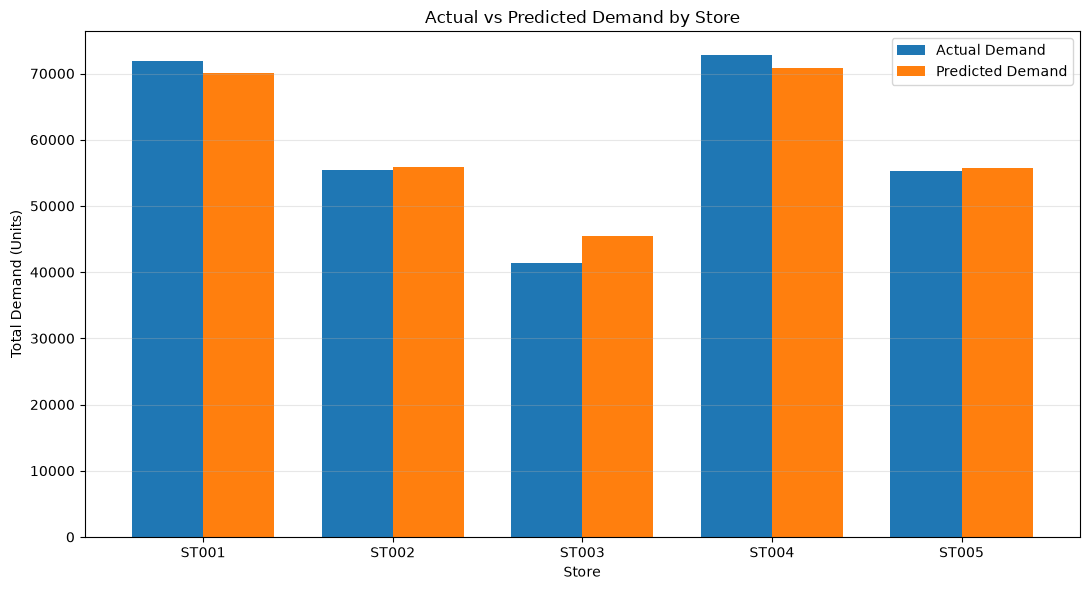

STORE DEMAND COMPARISON VISUALIZATION COMPLETED


In [56]:

# Section 42: Visualize Actual vs Predicted Demand by Store

import matplotlib.pyplot as plt

store_chart_data = store_performance.set_index(
    "store_id"
)[
    ["actual_demand", "predicted_demand"]
]

store_chart_data.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

plt.title("Actual vs Predicted Demand by Store")
plt.xlabel("Store")
plt.ylabel("Total Demand (Units)")
plt.xticks(rotation=0)
plt.legend(["Actual Demand", "Predicted Demand"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("STORE DEMAND COMPARISON VISUALIZATION COMPLETED")


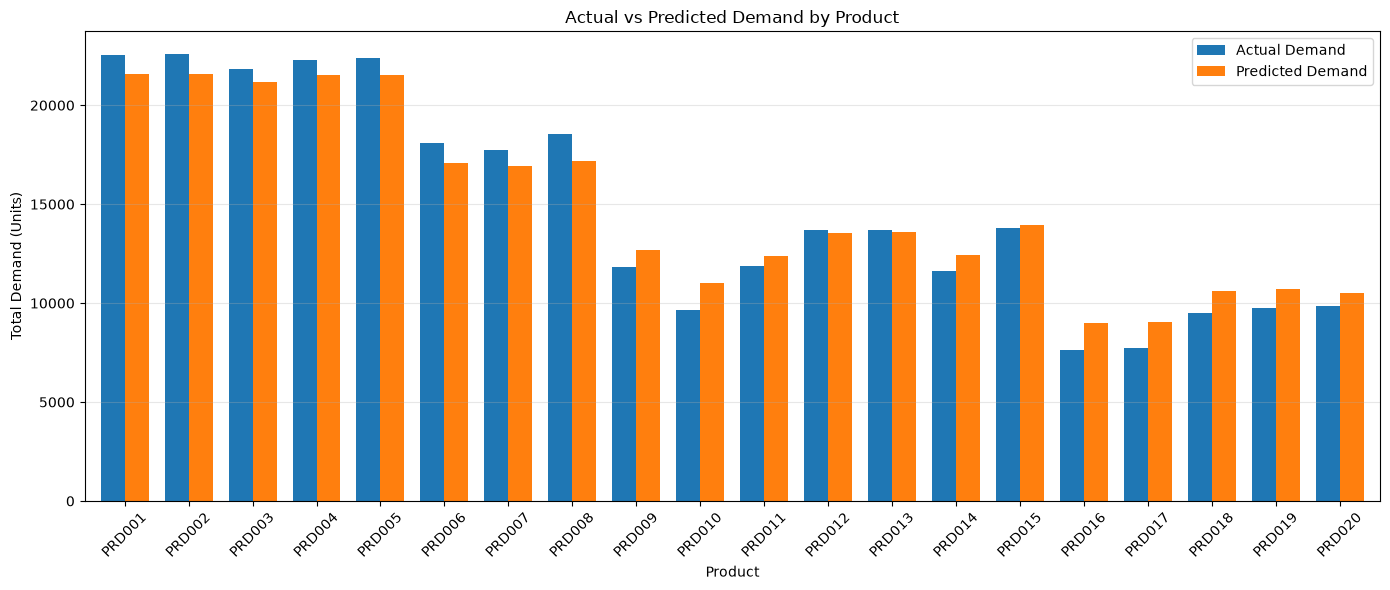

PRODUCT DEMAND COMPARISON VISUALIZATION COMPLETED


In [57]:

# Section 43: Visualize Actual vs Predicted Demand by Product

product_chart_data = product_performance.set_index(
    "product_id"
)[
    ["actual_demand", "predicted_demand"]
]

product_chart_data.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.75
)

plt.title("Actual vs Predicted Demand by Product")
plt.xlabel("Product")
plt.ylabel("Total Demand (Units)")
plt.xticks(rotation=45)
plt.legend(["Actual Demand", "Predicted Demand"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("PRODUCT DEMAND COMPARISON VISUALIZATION COMPLETED")


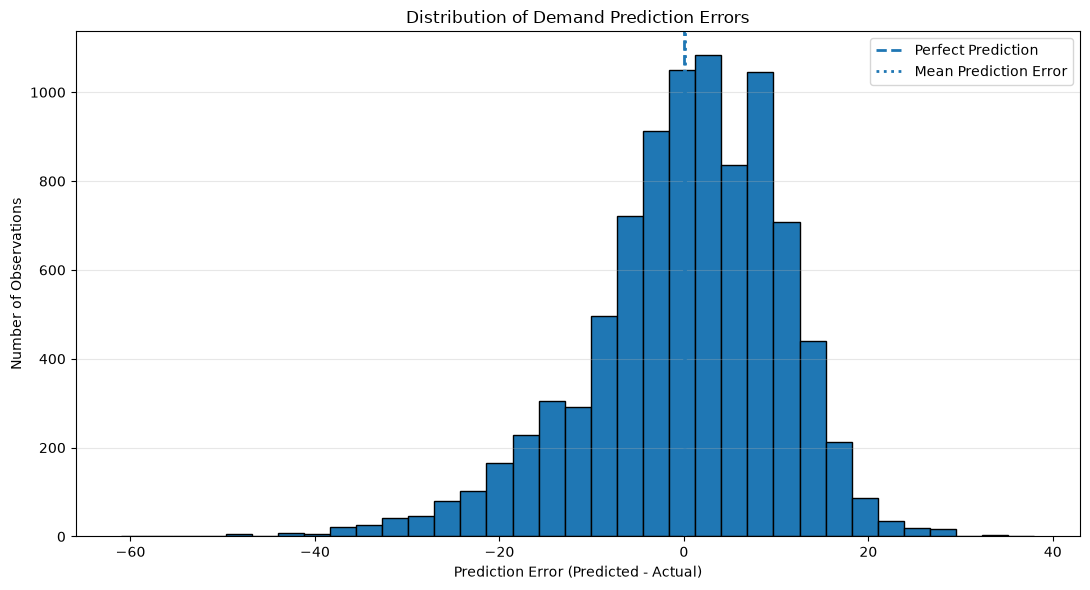

PREDICTION ERROR DISTRIBUTION VISUALIZATION COMPLETED


In [58]:

# Section 44: Visualize Prediction Error Distribution

plt.figure(figsize=(11, 6))

plt.hist(
    error_analysis["prediction_error"],
    bins=35,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.axvline(
    error_analysis["prediction_error"].mean(),
    linestyle=":",
    linewidth=2,
    label="Mean Prediction Error"
)

plt.title("Distribution of Demand Prediction Errors")
plt.xlabel("Prediction Error (Predicted - Actual)")
plt.ylabel("Number of Observations")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("PREDICTION ERROR DISTRIBUTION VISUALIZATION COMPLETED")


In [59]:
# Section 45: Generate Business Insights and Recommendations

best_store = store_performance.loc[
    store_performance["mean_absolute_error"].idxmin()
]

worst_store = store_performance.loc[
    store_performance["mean_absolute_error"].idxmax()
]

best_product = product_performance.loc[
    product_performance["mean_absolute_error"].idxmin()
]

worst_product = product_performance.loc[
    product_performance["mean_absolute_error"].idxmax()
]

overprediction_count = (
    error_analysis["error_type"] == "Overprediction"
).sum()

underprediction_count = (
    error_analysis["error_type"] == "Underprediction"
).sum()

exact_prediction_count = (
    error_analysis["error_type"] == "Exact Prediction"
).sum()

print("SMARTSERVE — BUSINESS INSIGHTS AND RECOMMENDATIONS")
print("=" * 70)

print("\n1. MODEL PERFORMANCE")
print(f"Deployment MAE: {mae:.2f} units")
print(f"Deployment RMSE: {rmse:.2f} units")
print(f"Deployment R2: {r2:.4f}")

print("\n2. PREDICTION ERROR DISTRIBUTION")
print(f"Overpredictions: {overprediction_count:,}")
print(f"Underpredictions: {underprediction_count:,}")
print(f"Exact predictions: {exact_prediction_count:,}")

print("\n3. STORE PERFORMANCE")
print(
    f"Best store by MAE: {best_store['store_id']} "
    f"({best_store['mean_absolute_error']:.2f})"
)
print(
    f"Store requiring attention: {worst_store['store_id']} "
    f"({worst_store['mean_absolute_error']:.2f})"
)

print("\n4. PRODUCT PERFORMANCE")
print(
    f"Best product by MAE: {best_product['product_id']} "
    f"({best_product['mean_absolute_error']:.2f})"
)
print(
    f"Product requiring attention: {worst_product['product_id']} "
    f"({worst_product['mean_absolute_error']:.2f})"
)

print("\n5. BUSINESS RECOMMENDATIONS")

recommendations = [
    "Use demand predictions as an input for daily inventory planning.",
    "Monitor high-demand products for potential understocking.",
    "Review low-demand products with substantial overprediction.",
    "Investigate store-level differences in forecasting accuracy.",
    "Use safety stock for products with larger underprediction errors.",
    "Monitor forecast errors regularly and update the model when justified.",
    "Evaluate future forecasts separately from historical predictions."
]

for number, recommendation in enumerate(recommendations, start=1):
    print(f"{number}. {recommendation}")

print("\nBUSINESS INSIGHTS GENERATION COMPLETED")


SMARTSERVE — BUSINESS INSIGHTS AND RECOMMENDATIONS

1. MODEL PERFORMANCE
Deployment MAE: 8.21 units
Deployment RMSE: 10.61 units
Deployment R2: 0.6198

2. PREDICTION ERROR DISTRIBUTION
Overpredictions: 4,863
Underpredictions: 3,803
Exact predictions: 334

3. STORE PERFORMANCE
Best store by MAE: ST003 (6.37)
Store requiring attention: ST004 (10.05)

4. PRODUCT PERFORMANCE
Best product by MAE: PRD016 (5.51)
Product requiring attention: PRD001 (11.57)

5. BUSINESS RECOMMENDATIONS
1. Use demand predictions as an input for daily inventory planning.
2. Monitor high-demand products for potential understocking.
3. Review low-demand products with substantial overprediction.
4. Investigate store-level differences in forecasting accuracy.
5. Use safety stock for products with larger underprediction errors.
6. Monitor forecast errors regularly and update the model when justified.
7. Evaluate future forecasts separately from historical predictions.

BUSINESS INSIGHTS GENERATION COMPLETED


In [60]:

# Section 46: Generate Inventory Recommendations

# Calculate historical underprediction errors.
error_analysis["underprediction_error"] = (
    error_analysis["actual_sales_qty"]
    - error_analysis["predicted_sales_qty"]
).clip(lower=0)

# Calculate demand and forecast risk by store and product.
inventory_recommendations = (
    error_analysis
    .groupby(["store_id", "product_id"])
    .agg(
        average_daily_demand=("predicted_sales_qty", "mean"),
        maximum_predicted_demand=("predicted_sales_qty", "max"),
        average_underprediction=("underprediction_error", "mean"),
        underprediction_std=("underprediction_error", "std")
    )
    .reset_index()
)

# Use overall historical error variability if a group
# does not have enough observations to calculate standard deviation.
overall_error_std = (
    error_analysis["underprediction_error"].std()
)

inventory_recommendations["underprediction_std"] = (
    inventory_recommendations["underprediction_std"]
    .fillna(overall_error_std)
)

# Provisional 95% one-sided safety-stock allowance.
inventory_recommendations["safety_stock"] = np.ceil(
    1.645 * inventory_recommendations["underprediction_std"]
)

# Recommended stock = average predicted demand + safety stock.
inventory_recommendations["recommended_stock"] = np.ceil(
    inventory_recommendations["average_daily_demand"]
    + inventory_recommendations["safety_stock"]
).astype(int)

inventory_recommendations = (
    inventory_recommendations.round(2)
)

print("SMARTSERVE — INVENTORY RECOMMENDATIONS")
print("=" * 70)

print("\nRecommendation dataset shape:")
print(inventory_recommendations.shape)

print("\nSample inventory recommendations:")
print(
    inventory_recommendations.head(15).to_string(index=False)
)

print("\nOverall inventory planning summary:")
print(
    inventory_recommendations[
        [
            "average_daily_demand",
            "safety_stock",
            "recommended_stock"
        ]
    ].mean().round(2)
)

print("\nTotal store-product combinations:")
print(len(inventory_recommendations))

print("\nINVENTORY RECOMMENDATIONS COMPLETED")


SMARTSERVE — INVENTORY RECOMMENDATIONS

Recommendation dataset shape:
(100, 8)

Sample inventory recommendations:
store_id product_id  average_daily_demand  maximum_predicted_demand  average_underprediction  underprediction_std  safety_stock  recommended_stock
   ST001     PRD001                 57.76                        85                     8.12                10.72          18.0                 76
   ST001     PRD002                 57.20                        85                     7.73                10.21          17.0                 75
   ST001     PRD003                 56.62                        76                     7.89                11.46          19.0                 76
   ST001     PRD004                 57.31                        79                     7.96                10.95          19.0                 77
   ST001     PRD005                 57.41                        79                     8.64                11.03          19.0                 77
   S

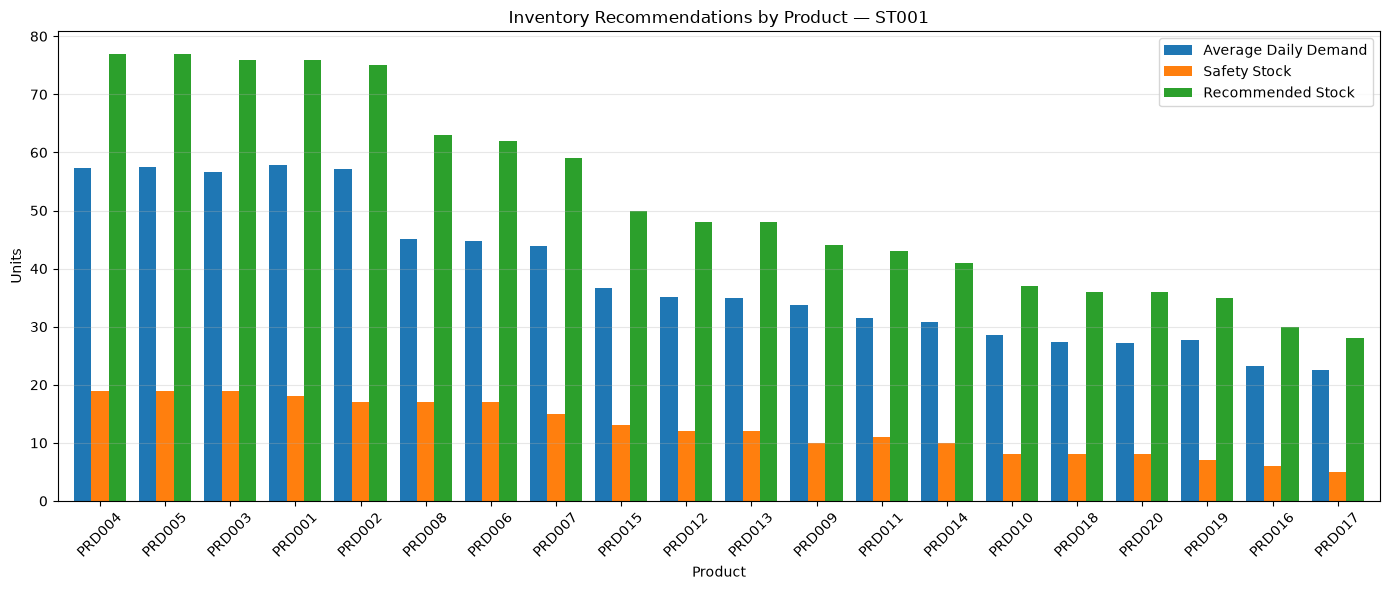

INVENTORY RECOMMENDATION VISUALIZATION COMPLETED — ST001


In [61]:

# Section 47: Visualize Recommended Stock by Product

selected_store = "ST001"

store_inventory = (
    inventory_recommendations[
        inventory_recommendations["store_id"] == selected_store
    ]
    .sort_values("recommended_stock", ascending=False)
    .set_index("product_id")
)

store_inventory[
    [
        "average_daily_demand",
        "safety_stock",
        "recommended_stock"
    ]
].plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title(
    f"Inventory Recommendations by Product — {selected_store}"
)

plt.xlabel("Product")
plt.ylabel("Units")
plt.xticks(rotation=45)
plt.legend(
    [
        "Average Daily Demand",
        "Safety Stock",
        "Recommended Stock"
    ]
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(
    f"INVENTORY RECOMMENDATION VISUALIZATION COMPLETED — {selected_store}"
)


In [62]:

# Section 48: Export Deployment Forecast Results

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

EXPORT_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "deployment"
)

EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Export historical prediction results.
forecast_results.to_csv(
    EXPORT_DIR / "historical_demand_predictions.csv",
    index=False
)

# Export store-level performance.
store_performance.to_csv(
    EXPORT_DIR / "store_forecast_performance.csv",
    index=False
)

# Export product-level performance.
product_performance.to_csv(
    EXPORT_DIR / "product_forecast_performance.csv",
    index=False
)

# Export inventory recommendations.
inventory_recommendations.to_csv(
    EXPORT_DIR / "inventory_recommendations.csv",
    index=False
)

print("SMARTSERVE — DEPLOYMENT EXPORT")
print("=" * 65)

print("\nExport directory:")
print(EXPORT_DIR)

print("\nExported files:")

for file_path in sorted(EXPORT_DIR.glob("*.csv")):
    print(
        f"{file_path.name} | "
        f"{file_path.stat().st_size:,} bytes"
    )

print("\nTotal exported files:")
print(len(list(EXPORT_DIR.glob("*.csv"))))

print("\nDEPLOYMENT EXPORT COMPLETED")


SMARTSERVE — DEPLOYMENT EXPORT

Export directory:
d:\Data Analysis Projects\SmartServe-Food-Intelligence\data\processed\deployment

Exported files:
historical_demand_predictions.csv | 359,945 bytes
inventory_recommendations.csv | 4,174 bytes
product_forecast_performance.csv | 1,312 bytes
store_forecast_performance.csv | 468 bytes

Total exported files:
4

DEPLOYMENT EXPORT COMPLETED


In [63]:

# Section 49: Validate Exported Files

export_files = {
    "historical_demand_predictions.csv": 9000,
    "store_forecast_performance.csv": 5,
    "product_forecast_performance.csv": 20,
    "inventory_recommendations.csv": 100
}

print("SMARTSERVE — DEPLOYMENT EXPORT VALIDATION")
print("=" * 70)

validation_results = []

for filename, expected_rows in export_files.items():

    file_path = EXPORT_DIR / filename

    if not file_path.exists():
        raise FileNotFoundError(
            f"Export file not found: {filename}"
        )

    exported_data = pd.read_csv(file_path)

    actual_rows = len(exported_data)

    validation_results.append({
        "File": filename,
        "Expected_Rows": expected_rows,
        "Actual_Rows": actual_rows,
        "Columns": len(exported_data.columns),
        "Status": (
            "PASS"
            if actual_rows == expected_rows
            else "FAIL"
        )
    })

validation_report = pd.DataFrame(validation_results)

print("\nExport validation report:")
print(validation_report.to_string(index=False))

if not (validation_report["Status"] == "PASS").all():
    raise ValueError("One or more deployment exports failed validation.")

print("\nAll exported files passed validation.")
print("\nDEPLOYMENT EXPORT VALIDATION COMPLETED")


SMARTSERVE — DEPLOYMENT EXPORT VALIDATION

Export validation report:
                             File  Expected_Rows  Actual_Rows  Columns Status
historical_demand_predictions.csv           9000         9000        6   PASS
   store_forecast_performance.csv              5            5       10   PASS
 product_forecast_performance.csv             20           20       10   PASS
    inventory_recommendations.csv            100          100        8   PASS

All exported files passed validation.

DEPLOYMENT EXPORT VALIDATION COMPLETED


In [64]:

# Section 50: Save Deployment Model and Feature Reference

import joblib

MODEL_DIR = PROJECT_ROOT / "models" / "deployment"

MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Save the selected trained model.
deployment_model_path = (
    MODEL_DIR / "gradient_boosting_deployment_model.pkl"
)

joblib.dump(
    deployment_model,
    deployment_model_path
)

# Save the exact model feature order.
feature_reference_path = (
    MODEL_DIR / "deployment_feature_names.csv"
)

pd.DataFrame({
    "feature_order": range(1, len(expected_features) + 1),
    "feature_name": expected_features
}).to_csv(
    feature_reference_path,
    index=False
)

print("SMARTSERVE — DEPLOYMENT MODEL ARTIFACTS")
print("=" * 65)

print("\nModel saved:")
print(deployment_model_path)

print("\nFeature reference saved:")
print(feature_reference_path)

print("\nExpected model features:")
print(len(expected_features))

print("\nModel file exists:")
print(deployment_model_path.exists())

print("\nFeature reference exists:")
print(feature_reference_path.exists())

print("\nDEPLOYMENT MODEL ARTIFACTS SAVED")


SMARTSERVE — DEPLOYMENT MODEL ARTIFACTS

Model saved:
d:\Data Analysis Projects\SmartServe-Food-Intelligence\models\deployment\gradient_boosting_deployment_model.pkl

Feature reference saved:
d:\Data Analysis Projects\SmartServe-Food-Intelligence\models\deployment\deployment_feature_names.csv

Expected model features:
110

Model file exists:
True

Feature reference exists:
True

DEPLOYMENT MODEL ARTIFACTS SAVED


In [65]:

# Section 51: Verify the Saved Deployment Model

# Load the saved deployment model.
loaded_deployment_model = joblib.load(
    deployment_model_path
)

# Load the saved feature reference.
saved_feature_reference = pd.read_csv(
    feature_reference_path
)

saved_features = saved_feature_reference[
    "feature_name"
].tolist()

# Verify feature count and order.
model_features = list(
    loaded_deployment_model.feature_names_in_
)

assert len(saved_features) == 110
assert saved_features == model_features

# Generate a small test prediction.
sample_features = deployment_features[
    saved_features
].head(5)

sample_predictions = loaded_deployment_model.predict(
    sample_features
)

print("SMARTSERVE — SAVED MODEL VERIFICATION")
print("=" * 65)

print("\nLoaded model:")
print(type(loaded_deployment_model).__name__)

print("\nSaved feature count:")
print(len(saved_features))

print("\nFeature order matches:")
print(saved_features == model_features)

print("\nSample input shape:")
print(sample_features.shape)

print("\nSample predictions:")
print(sample_predictions)

print("\nPrediction count:")
print(len(sample_predictions))

print("\nModel verification:")
print("PASSED" if len(sample_predictions) == 5 else "FAILED")

print("\nDEPLOYMENT MODEL VERIFICATION COMPLETED")


SMARTSERVE — SAVED MODEL VERIFICATION

Loaded model:
GradientBoostingRegressor

Saved feature count:
110

Feature order matches:
True

Sample input shape:
(5, 110)

Sample predictions:
[52.56239586 52.13730609 51.45418423 56.8842663  56.17452431]

Prediction count:
5

Model verification:
PASSED

DEPLOYMENT MODEL VERIFICATION COMPLETED


In [67]:

# Section 52: Deployment Completion Summary

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Recalculate deployment metrics.
actual = forecast_results["actual_sales_qty"]
predicted = forecast_results["predicted_sales_qty"]

deployment_mae = mean_absolute_error(actual, predicted)

deployment_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

deployment_r2 = r2_score(actual, predicted)

print("=" * 75)
print("SMARTSERVE — MODEL DEPLOYMENT AND FORECASTING SUMMARY")
print("=" * 75)

print("\n1. MODEL")
print("-" * 75)
print("Selected model: Gradient Boosting Regressor")
print("Model artifact:", deployment_model_path)
print("Expected features:", len(saved_features))

print("\n2. HISTORICAL PREDICTIONS")
print("-" * 75)
print("Prediction records:", len(forecast_results))
print("Stores:", forecast_results["store_id"].nunique())
print("Products:", forecast_results["product_id"].nunique())
print("MAE:", round(deployment_mae, 2))
print("RMSE:", round(deployment_rmse, 2))
print("R2:", round(deployment_r2, 4))

print("\n3. INVENTORY RECOMMENDATIONS")
print("-" * 75)
print("Store-product combinations:", len(inventory_recommendations))
print(
    "Average recommended stock:",
    round(inventory_recommendations["recommended_stock"].mean(), 2)
)

print("\n4. EXPORTED FILES")
print("-" * 75)
print("Export directory:", EXPORT_DIR)
print("CSV files:", len(list(EXPORT_DIR.glob("*.csv"))))

print("\n5. DEPLOYMENT ARTIFACTS")
print("-" * 75)
print("Model exists:", deployment_model_path.exists())
print("Feature reference exists:", feature_reference_path.exists())
print("Saved model verification: PASSED")

print("\n" + "=" * 75)
print("NOTEBOOK 06 — DEPLOYMENT WORKFLOW COMPLETED")
print("=" * 75)


SMARTSERVE — MODEL DEPLOYMENT AND FORECASTING SUMMARY

1. MODEL
---------------------------------------------------------------------------
Selected model: Gradient Boosting Regressor
Model artifact: d:\Data Analysis Projects\SmartServe-Food-Intelligence\models\deployment\gradient_boosting_deployment_model.pkl
Expected features: 110

2. HISTORICAL PREDICTIONS
---------------------------------------------------------------------------
Prediction records: 9000
Stores: 5
Products: 20
MAE: 8.21
RMSE: 10.61
R2: 0.6198

3. INVENTORY RECOMMENDATIONS
---------------------------------------------------------------------------
Store-product combinations: 100
Average recommended stock: 43.92

4. EXPORTED FILES
---------------------------------------------------------------------------
Export directory: d:\Data Analysis Projects\SmartServe-Food-Intelligence\data\processed\deployment
CSV files: 4

5. DEPLOYMENT ARTIFACTS
---------------------------------------------------------------------------
Mo